# Diffusion Distillation in Practice: Consistency · LADD · DMD · PDD

We take one pretrained text-to-image flow model, **Sana-600M (512px)**, and distill it into a **few-step** generator (`STUDENT_NFE`, default **4 steps**) with four different methods, on a single Colab GPU.

| | family | the student is trained to … | teacher cost / iter | extra trainable nets | data |
|---|---|---|---|---|---|
| **CM**: (multistep) Consistency Distillation | trajectory | jump to the end of its ODE segment, *self-consistently* along the teacher ODE | 1 CFG call | none (target = stop-grad student) | noised teacher samples |
| **LADD**: Latent Adversarial Diffusion Distillation | distribution, adversarial | fool a discriminator built on the *teacher's own features* | 1 backbone pass (discriminator) | discriminator heads | teacher samples = "real" |
| **DMD**: Distribution Matching Distillation (DMD2-style) | distribution, score-based | descend the reverse KL: move samples along $s_\text{real}-s_\text{fake}$ | 1 CFG call | "fake" score model | none (data-free) |
| **PDD**: Parallel Decoding Distillation | trajectory, pure regression | predict *L teacher steps in one forward pass* | 1–2 CFG calls | N output heads | noised teacher samples |

The table is a 2×2: **trajectory** methods (CM, PDD) keep the teacher's noise→image map, while **distribution** methods (LADD, DMD) only match the output distribution. Keep that in mind when you look at the samples.

**Runtime:** `Runtime → Change runtime type → T4 GPU` (the free tier is enough). Iteration budgets in `PROFILES` are sized for a few minutes per method on a T4, and every training cell prints its measured it/s and ETA. Text embeddings, teacher samples and trained adapters are cached in `CACHE_DIR`; mount Google Drive and point `CACHE_DIR` there to survive disconnects.

**Map:** 0 setup → 1 tools → 2 teacher & dataset → 3 CM → 4 LADD → 5 DMD → 6 PDD → 7 comparison → 8 exercises.

## Conventions (the same as SD3 / Flux / Sana)

* $t=1$ is pure noise, $t=0$ is data: $\;x_t=(1-t)\,x_0+t\,\varepsilon$, and the velocity is $v=\varepsilon-x_0$.
* From any velocity prediction: $\hat x_0 = x_t - t\,v$. One Euler step: $x_{t'} = x_t + (t'-t)\,v$.
* The network receives `timestep = 1000·t`. Time grids are **shifted**, $t\mapsto \frac{s\,t}{1+(s-1)\,t}$, which puts more steps at high noise; $s$ is `SHIFT`, read from Sana's scheduler config.
* CFG is **baked into every distillation target** ($w=4.5$): $v^w=v_\varnothing+w\,(v_c-v_\varnothing)$. Students never use CFG, so they cost 1 NFE per step instead of 2.

## Why Sana-600M-512px fits in Colab

* It is natively a flow-matching model (velocity prediction), so the formulas above apply verbatim.
* Its DC-AE autoencoder downsamples 32×, so a 512×512 image is a **16×16×32 latent = 256 tokens**. That is the cost of DiT-XL/2 at 256px, but for text-to-image at 512px.
* fp16 transformer weights are officially supported, which matters because a T4 has no fast bf16. The Gemma-2 text encoder and DC-AE need fp32/bf16; we use the text encoder once to cache the prompt embeddings, then delete it.
* **One frozen copy of the 600M weights** serves as the teacher, every student, DMD's "fake" score and LADD's discriminator backbone. Everything trainable is a LoRA adapter (or a small head) that we switch on and off, so we hold 1.2 GB of weights instead of 3–4 model copies.

# 0. Setup

In [1]:
# Colab only (locally use the prepared .venv). Colab already ships torch; Sana needs a recent diffusers/transformers.
import sys
if "google.colab" in sys.modules:
    !pip install -q -U diffusers transformers accelerate peft sentencepiece
    # Colab's preinstalled torchao is older than what the newest diffusers imports (FqnToConfig) and we don't use it.
    # If you already hit that ImportError: run this cell, then Runtime -> Restart session.
    !pip uninstall -y -q torchao

In [2]:
import os, gc, math, time, json, random, inspect, contextlib
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32   # frozen Sana weights + activations (T4: no fast bf16;
                                                               # on Apple MPS fp16 is not faster, so fp32, no GradScaler)
MODEL_ID = "Efficient-Large-Model/Sana_600M_512px_diffusers"
DATASET_ID = "leffff/diffusion-distillation-workshop"   # prompts + Gemma embeddings + teacher latents + images
USE_HF_DATA = True    # False: encode prompts with Gemma-2 and sample the teacher yourself (slow, needs ~10 GB more)
CACHE_DIR = "/content/distill_cache" if os.path.isdir("/content") else "./distill_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
torch.backends.cuda.matmul.allow_tf32 = True


def detect_profile():
    if DEVICE != "cuda":
        return DEVICE
    mem = torch.cuda.get_device_properties(0).total_memory / 2**30
    return "A100" if mem > 35 else ("L4" if mem > 20 else "T4")


# Every speed knob lives here. n_data = number of teacher samples (one per training prompt).
PROFILES = {
    "T4":   dict(batch=4,  n_data=512,  iters=dict(cm=2000, ladd=1600, dmd=3000, pdd=1600)),
    "L4":   dict(batch=8,  n_data=1024, iters=dict(cm=3000, ladd=2400, dmd=4000, pdd=2400)),
    "A100": dict(batch=16, n_data=2048, iters=dict(cm=4000, ladd=3000, dmd=6000, pdd=3000)),
    "mps":  dict(batch=4,  n_data=512,  iters=dict(cm=800,  ladd=600,  dmd=1200, pdd=600)),   # Apple Silicon (~2 s/it)
    "cpu":  dict(batch=2,  n_data=8,    iters=dict(cm=2,   ladd=2,   dmd=6,    pdd=2)),   # smoke test only
}
PROFILE = detect_profile()
P = PROFILES[PROFILE]
TRAIN_MINUTES = 5     # wall-clock budget per method: training stops at this time or at the iteration cap, whichever first
ITER_SCALE = 1.0      # multiply every method's iteration cap (set TRAIN_MINUTES = None to train for exactly the cap)
P["iters"] = {k: max(1, int(v * ITER_SCALE)) for k, v in P["iters"].items()}

GUIDANCE = 4.5        # Sana's default CFG scale; baked into every student
TEACHER_STEPS = 20    # reference sampler: Euler, 2 NFE per step because of CFG
STUDENT_NFE = 4       # every student is trained for this many network evaluations (the single knob for all methods)
LORA_RANK = 32
SEED = 0
random.seed(SEED); torch.manual_seed(SEED)
print(f"device={DEVICE}  profile={PROFILE}  {P}")

device=cuda  profile=A100  {'batch': 16, 'n_data': 2048, 'iters': {'cm': 4000, 'ladd': 3000, 'dmd': 6000, 'pdd': 3000}}


### Data

By default (`USE_HF_DATA = True`) we download the workshop dataset [`leffff/diffusion-distillation-workshop`](https://huggingface.co/datasets/leffff/diffusion-distillation-workshop). It holds 4096 diverse prompts from *open-image-preferences* (12 styles) and 64 *PartiPrompts* for evaluation. For each prompt it stores the Gemma-2 prompt embeddings, the teacher's latent and the decoded image, all made with this exact teacher. So we never load the 2.6B text encoder and never spend GPU time sampling the teacher.

Fallback (`USE_HF_DATA = False`): a deliberately **narrow** templated domain (animals × styles × places), encoded and sampled locally. It is slower to prepare but converges in fewer steps, because the distribution is much simpler.

In [3]:
SUBJECTS = ["a corgi", "a red fox", "a tabby cat", "a snowy owl", "a giant panda", "a golden retriever puppy",
            "a lion", "a hummingbird", "a koala", "a raccoon", "a white horse", "an emperor penguin",
            "a hedgehog", "a scarlet macaw", "a sea turtle", "a polar bear"]
STYLES = ["a professional photo of", "a watercolor painting of", "an oil painting of", "a 3D render of",
          "a pencil sketch of", "a pixel art illustration of", "an anime illustration of", "a cinematic still of"]
PLACES = ["in a snowy forest", "on a beach at sunset", "in a cozy library", "on a mountain peak",
          "in a field of sunflowers", "on a neon-lit city street at night", "near a coral reef",
          "in a misty bamboo forest", "on the surface of the moon", "in a medieval castle hall"]

ALL_PROMPTS = [f"{st} {su} {pl}" for su in SUBJECTS for st in STYLES for pl in PLACES]   # 1280 combinations
random.Random(SEED).shuffle(ALL_PROMPTS)
EVAL_PROMPTS = ALL_PROMPTS[:4] + ["a bowl of ramen with a soft-boiled egg, studio photo",    # out of domain
                                  "a red vintage car parked on a rainy street, cinematic"]
TRAIN_PROMPTS = ALL_PROMPTS[4:4 + P["n_data"]]
print(len(TRAIN_PROMPTS), "train prompts, e.g.:", TRAIN_PROMPTS[:3])

1276 train prompts, e.g.: ['an anime illustration of a lion on a neon-lit city street at night', 'a watercolor painting of a giant panda in a misty bamboo forest', 'a cinematic still of a lion in a field of sunflowers']


### Text embeddings and teacher samples

Sana conditions on the last hidden states of Gemma-2-2B, prefixed with a "complex human instruction" (CHI), computed by the pipeline's own `encode_prompt`.

* **HF dataset (default):** embeddings and teacher latents are already in the dataset. We download only as many 512-row shards as `P["n_data"]` needs and read only the tensor columns.
* **Fallback:** encode with Gemma-2, cache the result, free the encoder. Gemma-2 overflows in fp16, so on a T4 it runs in fp32 (≈10 GB, which fits before the transformer is loaded).

`MAX_SEQ=128` instead of Sana's 300: prompts are right-padded and the padding is masked out of cross-attention, so for short prompts the embeddings are identical while cross-attention gets cheaper.

In [4]:
from huggingface_hub import hf_hub_download, list_repo_files
import pyarrow.parquet as pq
from safetensors.torch import load_file

MAX_SEQ = 128
N_EVAL_SHOW = 6       # evaluation prompts shown in every comparison grid


def load_hf_split(split, n):
    """First n rows of a split: prompts, prompt embeddings/masks, teacher latents (images are not downloaded)."""
    meta = json.load(open(hf_hub_download(DATASET_ID, "meta.json", repo_type="dataset")))
    files = sorted(f for f in list_repo_files(DATASET_ID, repo_type="dataset") if f.startswith(f"data/{split}-"))
    cols, out = ["prompt", "latent", "prompt_embeds", "prompt_attention_mask"], {}
    for f in files:
        if len(out.get("prompt", [])) >= n:
            break
        t = pq.read_table(hf_hub_download(DATASET_ID, f, repo_type="dataset"), columns=cols).to_pydict()
        for c in cols:
            out.setdefault(c, []).extend(t[c])
    k = min(n, len(out["prompt"]))
    arr = lambda c, dt, shape: torch.from_numpy(np.stack([np.frombuffer(b, dt).reshape(shape) for b in out[c][:k]]))
    return dict(prompts=out["prompt"][:k], lat=arr("latent", np.float16, meta["latent_shape"]),
                emb=arr("prompt_embeds", np.float16, meta["prompt_embeds_shape"]),
                mask=arr("prompt_attention_mask", np.uint8, meta["prompt_embeds_shape"][:1]).long())


if USE_HF_DATA:
    tr, ev = load_hf_split("train", P["n_data"]), load_hf_split("eval", N_EVAL_SHOW)
    null = load_file(hf_hub_download(DATASET_ID, "null_prompt_embeds.safetensors", repo_type="dataset"))
    TRAIN_PROMPTS, EVAL_PROMPTS = tr["prompts"], ev["prompts"]
    TEXT = dict(prompts=TRAIN_PROMPTS + EVAL_PROMPTS, emb=torch.cat([tr["emb"], ev["emb"]]),
                mask=torch.cat([tr["mask"], ev["mask"]]), null_emb=null["null_prompt_embeds"],
                null_mask=null["null_prompt_attention_mask"].long())
    DATA = dict(lat=tr["lat"], prompt_idx=torch.arange(len(TRAIN_PROMPTS)))
    print(f"HF dataset: {len(TRAIN_PROMPTS)} train / {len(EVAL_PROMPTS)} eval prompts, latents {tuple(DATA['lat'].shape)}")
    for p in EVAL_PROMPTS:
        print("  eval:", p)
emb_path = f"{CACHE_DIR}/text_embeds_{len(TRAIN_PROMPTS)}.pt"
if USE_HF_DATA:
    pass
elif os.path.exists(emb_path):
    TEXT = torch.load(emb_path)
else:
    from diffusers import SanaPipeline
    te_dtype = torch.bfloat16 if DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float32
    try:
        pipe = SanaPipeline.from_pretrained(MODEL_ID, transformer=None, vae=None, torch_dtype=torch.float16, variant="fp16")
    except Exception:
        pipe = SanaPipeline.from_pretrained(MODEL_ID, transformer=None, vae=None, torch_dtype=torch.float16)
    pipe.text_encoder.to(DEVICE, te_dtype)          # converted parameter by parameter -> low peak memory
    chi = inspect.signature(SanaPipeline.__call__).parameters["complex_human_instruction"].default
    prompts, embs, masks = TRAIN_PROMPTS + EVAL_PROMPTS, [], []
    t0 = time.time()
    with torch.no_grad():
        for i in range(0, len(prompts), 16):
            e, m, ne, nm = pipe.encode_prompt(prompts[i:i + 16], do_classifier_free_guidance=True, negative_prompt="",
                                              device=DEVICE, max_sequence_length=MAX_SEQ,
                                              complex_human_instruction=chi)
            embs.append(e.half().cpu()); masks.append(m.cpu())
    TEXT = dict(prompts=prompts, emb=torch.cat(embs), mask=torch.cat(masks),
                null_emb=ne[:1].half().cpu(), null_mask=nm[:1].cpu())
    torch.save(TEXT, emb_path)
    print(f"encoded {len(prompts)} prompts in {time.time() - t0:.0f}s")
    del pipe; gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
print("text embeddings:", tuple(TEXT["emb"].shape), "| null:", tuple(TEXT["null_emb"].shape))

HF dataset: 2048 train / 6 eval prompts, latents (2048, 32, 16, 16)
  eval: A raccoon wearing formal clothes, wearing a tophat and holding a cane. The raccoon is holding a garbage bag. Oil painting in the style of Egyptian tomp hieroglyphics.
  eval: a green pepper to the left of a red pepper
  eval: a long chemtrail trailing an airplane in a blue sky
  eval: graffiti spelling BE KIND on white subway tile
  eval: a witch riding a broom
  eval: five green peppers to the right of two red onions
text embeddings: (2054, 128, 2304) | null: (1, 128, 2304)


In [5]:
from diffusers import SanaTransformer2DModel, AutoencoderDC
from huggingface_hub import hf_hub_download


def load_component(cls, subfolder, dtype):
    try:
        return cls.from_pretrained(MODEL_ID, subfolder=subfolder, torch_dtype=dtype, variant="fp16")
    except Exception:
        return cls.from_pretrained(MODEL_ID, subfolder=subfolder, torch_dtype=dtype)


transformer = load_component(SanaTransformer2DModel, "transformer", DTYPE).to(DEVICE).eval().requires_grad_(False)
vae = load_component(AutoencoderDC, "vae", torch.float32).to(DEVICE).eval().requires_grad_(False)  # DC-AE: fp32
SHIFT = float(json.load(open(hf_hub_download(MODEL_ID, "scheduler/scheduler_config.json"))).get("flow_shift") or 3.0)
RESOLUTION = 512
LAT_C, LAT_HW = transformer.config.in_channels, RESOLUTION // vae.spatial_compression_ratio
print(f"transformer: {sum(p.numel() for p in transformer.parameters()) / 1e6:.0f}M params, "
      f"{len(transformer.transformer_blocks)} blocks | latent {LAT_C}x{LAT_HW}x{LAT_HW} | SHIFT={SHIFT}")

/home/jovyan/novitskiy/ddw_venv/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


transformer: 592M params, 28 blocks | latent 32x16x16 | SHIFT=3.0


# 1. Tools

## 1.1 One frozen model, many adapters (peft LoRA)

All trainable parts are [peft](https://github.com/huggingface/peft) LoRA adapters on **one** frozen transformer, added through diffusers' `transformer.add_adapter(LoraConfig, adapter_name=...)`. `HUB.use(name)` selects which adapter is active:

* `velocity(x, t, cond)` with `adapter=None` is the **teacher** (`disable_adapters()`);
* `velocity(x, t, cond, "cm")` is the **CM student**, `"dmd_fake"` is DMD's fake score, and so on (`set_adapter(name)`).

LoRA targets attention q/k/v/out and Sana's 1×1-conv GLU-MLP (`conv_inverted`, `conv_point`). We use `init_lora_weights="gaussian"`, which still sets $B=0$, so every adapter starts exactly as the teacher.

⚠️ **Two peft details that silently break distillation**, both handled in the code below:
1. `set_adapter()` / `disable_adapters()` set `requires_grad=False` on the adapters they switch off. We switch adapters **inside one iteration** (student forward → teacher → fake → `backward()`), so without care the student's gradients are simply dropped: zero gradients, no error. `HUB` turns `requires_grad` back on after every switch.
2. On an fp16 base, peft creates the LoRA weights in **fp16**. We cast them to fp32 master weights; peft then computes the LoRA branch in fp32 and casts the result back. The loss is scaled with `GradScaler`. We do **not** use `torch.autocast`, because Sana's linear attention relies on explicit fp32 matmuls that autocast would downcast.

`GridHead` is not LoRA: it replaces the final projection `proj_out`. For PDD it holds **N copies of the teacher's head**, so one forward pass returns N velocities.

In [6]:
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict

LORA_TARGETS = ["to_q", "to_k", "to_v", "to_out.0", "conv_inverted", "conv_point",   # attention + 1x1-conv MLP
                "proj_out.base"]                                                     # final projection (as in our SD3 runs)


class AdapterHub:
    """Selects the active peft adapter of the shared transformer: use(None) = plain teacher, use("cm") = CM student."""
    def __init__(self, model):
        self.model, self.active = model, None

    def lora_params(self, name=None):
        return [p for n, p in self.model.named_parameters()
                if "lora_" in n and (name is None or f".{name}." in n)]

    def _apply(self, name):
        if not getattr(self.model, "_hf_peft_config_loaded", False):
            return                                         # no adapters yet: the model IS the teacher
        if name is None:
            self.model.disable_adapters()
        else:
            self.model.enable_adapters()
            self.model.set_adapter(name)
        for p in self.lora_params():                       # peft just set requires_grad=False on the inactive ones
            p.requires_grad_(True)

    def sync(self):
        self._apply(self.active)

    @contextlib.contextmanager
    def use(self, name):
        prev = self.active
        if name != prev:
            self._apply(name); self.active = name
        try:
            yield
        finally:
            if self.active != prev:
                self._apply(prev); self.active = prev


class GridHead(nn.Module):
    """Replaces transformer.proj_out. Normally it IS the teacher's projection; when the active adapter owns a grid
    (PDD) it outputs N velocities at once. All N copies are initialised from the teacher's weights."""
    def __init__(self, base, patch_size):
        super().__init__()
        self.base, self.p = base, patch_size
        self.grid_w, self.grid_b, self.n_grid = nn.ParameterDict(), nn.ParameterDict(), {}

    weight = property(lambda self: self.base.weight)
    bias = property(lambda self: self.base.bias)

    def add_grid(self, name, n):
        W, b = self.base.weight.detach().float(), self.base.bias.detach().float()
        pp = self.p * self.p
        C, D = W.shape[0] // pp, W.shape[1]
        # Sana unpatchifies the last dim as (p, p, channels). Repeating each per-pixel channel block N times makes
        # the model's own reshape return (B, N*C, H, W) with channel index k*C + c. (A naive W.repeat(N, 1) is only
        # correct for patch_size = 1; the PDD paper stresses this "correctly reshaped weights" detail.)
        W = W.view(pp, 1, C, D).expand(pp, n, C, D).reshape(pp * n * C, D)
        b = b.view(pp, 1, C).expand(pp, n, C).reshape(-1)
        self.grid_w[name], self.grid_b[name] = nn.Parameter(W.clone()), nn.Parameter(b.clone())
        self.n_grid[name] = n
        return [self.grid_w[name], self.grid_b[name]]

    def forward(self, h):
        name = HUB.active
        if name in self.n_grid:
            return F.linear(h, self.grid_w[name].to(h.dtype), self.grid_b[name].to(h.dtype))
        return self.base(h)

In [7]:
HUB = AdapterHub(transformer)
if not isinstance(transformer.proj_out, GridHead):
    transformer.proj_out = GridHead(transformer.proj_out, transformer.config.patch_size)
GRID_HEAD = transformer.proj_out
print("LoRA targets:", LORA_TARGETS)

LoRA targets: ['to_q', 'to_k', 'to_v', 'to_out.0', 'conv_inverted', 'conv_point', 'proj_out.base']


## 1.2 Flow-matching helpers, the teacher, and samplers

In [8]:
# ------------------------------------------------------------------ flow matching (t = 1 noise, t = 0 data)
def bc(t, x):
    """Broadcast a scalar or per-sample (B,) time to x's shape."""
    t = torch.as_tensor(t, device=x.device, dtype=x.dtype)
    return t.reshape(-1, *([1] * (x.ndim - 1)))


def shift_t(t, s=None):
    s = SHIFT if s is None else s
    return s * t / (1 + (s - 1) * t)


def make_grid(n, s=None, device=None):
    """n+1 shifted times: 1 = t_0 > t_1 > ... > t_n = 0."""
    return shift_t(torch.linspace(1.0, 0.0, n + 1, device=device or DEVICE), s)


def add_noise(x0, eps, t):  return (1 - bc(t, x0)) * x0 + bc(t, x0) * eps
def x0_from_v(x, v, t):     return x - bc(t, x) * v
def euler(x, v, t, t_next): return x + bc(t_next - t, x) * v


def as_batch(t, b):
    t = torch.as_tensor(t, device=DEVICE, dtype=torch.float32).reshape(-1)
    return t.expand(b) if t.numel() == 1 else t


# ------------------------------------------------------------------ text conditions
@dataclass
class Cond:
    emb: torch.Tensor    # (B, L, 2304) Gemma-2 hidden states
    mask: torch.Tensor   # (B, L) attention mask

    def __len__(self):
        return self.emb.shape[0]


def get_cond(idx):
    idx = torch.as_tensor(idx).cpu()
    return Cond(TEXT["emb"][idx].to(DEVICE), TEXT["mask"][idx].to(DEVICE))


def null_cond(b):
    return Cond(TEXT["null_emb"].to(DEVICE).expand(b, -1, -1), TEXT["null_mask"].to(DEVICE).expand(b, -1))


def cat_cond(a, b):
    return None if a is None else Cond(torch.cat([a.emb, b.emb]), torch.cat([a.mask, b.mask]))


# ------------------------------------------------------------------ the ONE network call every method uses
def velocity(x, t, cond, adapter=None):
    """adapter=None -> frozen teacher;  'cm' / 'dmd' / 'dmd_fake' / ... -> that LoRA (and head).
    x: (B,C,H,W) float32 latents, t: (B,) or scalar time in [0,1]. Returns float32 (B,C,H,W) (PDD: (B,N*C,H,W))."""
    with HUB.use(adapter):
        out = transformer(hidden_states=x.to(DTYPE), encoder_hidden_states=cond.emb.to(DTYPE),
                          encoder_attention_mask=cond.mask, timestep=as_batch(t, x.shape[0]) * 1000,
                          return_dict=False)[0]
    return out.float()


@torch.no_grad()
def teacher_v(x, t, cond, w=GUIDANCE):
    """Teacher velocity with classifier-free guidance (conditional + unconditional in one batch)."""
    b = x.shape[0]
    t = as_batch(t, b)
    v_c, v_u = velocity(torch.cat([x, x]), torch.cat([t, t]), cat_cond(cond, null_cond(b))).chunk(2)
    return v_u + w * (v_c - v_u)


# ------------------------------------------------------------------ samplers
@torch.no_grad()
def sample_teacher(cond, noise, steps=TEACHER_STEPS, w=GUIDANCE):
    ts, x = make_grid(steps), noise
    for i in range(steps):
        x = euler(x, teacher_v(x, ts[i], cond, w), ts[i], ts[i + 1])
    return x


@torch.no_grad()
def sample_student(adapter, cond, noise, nfe=STUDENT_NFE, mode="ode"):
    """mode='ode'     : deterministic Euler jumps along the student's velocity (CM, trajectory methods)
       mode='renoise' : predict x0, re-noise it with FRESH noise to the next time (LADD / DMD, as in ADD/DMD2)"""
    ts, x = make_grid(nfe), noise
    for i in range(nfe):
        v = velocity(x, ts[i], cond, adapter)
        if mode == "ode":
            x = euler(x, v, ts[i], ts[i + 1])
        else:
            x0 = x0_from_v(x, v, ts[i])
            x = x0 if i == nfe - 1 else add_noise(x0, torch.randn_like(x0), ts[i + 1])
    return x


def latent_noise(b, gen=None):
    return torch.randn(b, LAT_C, LAT_HW, LAT_HW, device=DEVICE, generator=gen)


# ------------------------------------------------------------------ decoding and plotting
@torch.no_grad()
def decode(lat):
    """Latents -> (B, H, W, 3) images in [0, 1]."""
    out = []
    for z in lat.split(4):
        img = vae.decode(z.to(DEVICE, vae.dtype) / vae.config.scaling_factor, return_dict=False)[0]
        out.append((img.float().clamp(-1, 1) * 0.5 + 0.5).permute(0, 2, 3, 1).cpu())
    return torch.cat(out)


def show_rows(rows, row_titles, col_titles=None, size=2.4):
    """rows: list of latent batches with the same batch size -> one image row per entry."""
    imgs = [decode(r) for r in rows]
    n_r, n_c = len(imgs), imgs[0].shape[0]
    fig, axs = plt.subplots(n_r, n_c, figsize=(size * n_c, size * n_r), squeeze=False)
    for i in range(n_r):
        for j in range(n_c):
            ax = axs[i][j]
            ax.imshow(imgs[i][j].numpy()); ax.set_xticks([]); ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(row_titles[i], fontsize=9)
            if i == 0 and col_titles is not None:
                ax.set_title(col_titles[j], fontsize=7)
    plt.tight_layout(); plt.show()

## 1.3 Training utilities

In [9]:
def add_lora(name, rank=LORA_RANK, alpha=None, fresh=True):
    """(Re)creates peft LoRA adapter `name` and returns its parameters (fresh=False: keep training an existing one)."""
    exists = getattr(transformer, "_hf_peft_config_loaded", False) and name in transformer.peft_config
    if exists and not fresh:
        return HUB.lora_params(name)
    if exists:
        transformer.delete_adapters(name)
    transformer.add_adapter(LoraConfig(r=rank, lora_alpha=alpha or rank, init_lora_weights="gaussian",
                                       target_modules=LORA_TARGETS), adapter_name=name)
    params = HUB.lora_params(name)
    for p in params:
        p.data = p.data.float()            # fp32 master weights on the fp16 base
        p.requires_grad_(True)
    HUB.sync()                             # add_adapter() activated `name`; restore whatever HUB had active
    return params


def n_params(params):
    return sum(p.numel() for p in params)


def adamw(params, lr, betas=(0.9, 0.99)):
    return torch.optim.AdamW(params, lr=lr, betas=betas, weight_decay=0.0)


def new_scaler():
    return torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda" and DTYPE == torch.float16))


def opt_step(loss, opt, scaler, params, clip=1.0):
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    grad_norm = torch.nn.utils.clip_grad_norm_(params, clip).item()     # before clipping
    scaler.step(opt)
    scaler.update()
    opt.zero_grad(set_to_none=True)
    return grad_norm


def data_batch(b):
    """Random teacher samples x0 (float32 latents) and their prompt conditions."""
    i = torch.randint(0, DATA["lat"].shape[0], (b,))
    return DATA["lat"][i].to(DEVICE).float(), get_cond(DATA["prompt_idx"][i])


def prompt_batch(b):
    """Prompt conditions only (for data-free methods)."""
    return get_cond(torch.randint(0, len(TRAIN_PROMPTS), (b,)))


class Meter:
    """Logs losses, prints every ~30 s, and enforces the TRAIN_MINUTES wall-clock budget (see `done`)."""
    def __init__(self, name, total, print_every_s=30, minutes="default"):
        self.name, self.total, self.print_every_s = name, total, print_every_s
        self.minutes = TRAIN_MINUTES if minutes == "default" else minutes
        self.hist, self.buf, self.t0, self.last_print, self.its = {}, {}, time.time(), time.time(), 0

    def done(self):
        """True once the time budget is used up: call at the top of the training loop and break."""
        if self.minutes is not None and time.time() - self.t0 > self.minutes * 60:
            print(f"[{self.name}] time budget of {self.minutes} min reached after {self.its} iterations")
            return True
        return False

    def log(self, it, **vals):
        self.its = it + 1
        for k, v in vals.items():
            self.hist.setdefault(k, []).append(v)
            self.buf.setdefault(k, []).append(v)
        now = time.time()
        if now - self.last_print > self.print_every_s or it + 1 == self.total:
            el = now - self.t0
            ips = (it + 1) / el
            eta = (self.total - it - 1) / ips
            if self.minutes is not None:
                eta = min(eta, self.minutes * 60 - el)
            msg = " | ".join(f"{k} {np.mean(v):.4f}" for k, v in self.buf.items())
            print(f"[{self.name}] {it + 1:>5}/{self.total} | {msg} | {ips:.2f} it/s | ETA {max(eta, 0) / 60:.1f} min")
            self.buf, self.last_print = {}, now

    def plot(self, keys=None):
        hist = {k: v for k, v in self.hist.items() if keys is None or k in keys}
        if not hist:
            print(f"[{self.name}] nothing logged yet for {keys}")
            return
        fig, axs = plt.subplots(1, len(hist), figsize=(4 * len(hist), 2.4), squeeze=False)
        for ax, (k, v) in zip(axs[0], hist.items()):
            w = max(1, len(v) // 20)
            ax.plot(v, alpha=0.3)
            ax.plot(np.arange(w - 1, len(v)), np.convolve(v, np.ones(w) / w, mode="valid"))
            ax.set_title(f"{self.name}: {k}", fontsize=9)
        plt.tight_layout(); plt.show()


def save_adapter(name):
    sd = {k: v.detach().cpu() for k, v in get_peft_model_state_dict(transformer, adapter_name=name).items()}
    if name in GRID_HEAD.n_grid:
        sd["grid.w"], sd["grid.b"] = GRID_HEAD.grid_w[name].detach().cpu(), GRID_HEAD.grid_b[name].detach().cpu()
    torch.save(sd, f"{CACHE_DIR}/adapter_{name}.pt")


def load_adapter(name):
    """Instructor tip: train once on a big GPU, share adapter_*.pt, students load it here and skip training."""
    sd = torch.load(f"{CACHE_DIR}/adapter_{name}.pt")
    grid = {k: sd.pop(k) for k in ["grid.w", "grid.b"] if k in sd}
    rank = next(v.shape[0] for k, v in sd.items() if "lora_A" in k)
    add_lora(name, rank)
    set_peft_model_state_dict(transformer, sd, adapter_name=name)
    if grid:
        GRID_HEAD.add_grid(name, grid["grid.w"].shape[0] // GRID_HEAD.base.weight.shape[0])
        GRID_HEAD.grid_w[name].data.copy_(grid["grid.w"]); GRID_HEAD.grid_b[name].data.copy_(grid["grid.b"])


# ------------------------------------------------------------------ oracle for unit tests of the losses
def make_oracle(x0_star):
    """Exact velocity field when the data is a single point x0*: every trajectory is a straight line,
    v(x, t) = (x - x0*) / t. Any correct distillation loss must be (almost) zero for a perfect student."""
    def v(x, t, cond=None):
        return (x - x0_star) / bc(t, x).clamp_min(1e-6)
    return v


def toy_problem(b=3, shape=(4, 8, 8), seed=0):
    x0_star = torch.randn(1, *shape, generator=torch.Generator().manual_seed(seed)).to(DEVICE)
    return x0_star.expand(b, *shape).clone(), make_oracle(x0_star), x0_star

# 2. The teacher and its synthetic dataset

First, the problem we are solving: the teacher needs ~20 steps with CFG (40 NFE). With `STUDENT_NFE` or 1 Euler steps the images are blurry averages, because one big Euler step lands on $\mathbb E[x_0\mid x_t]$.

teacher, 20 steps: 0.19 s/image


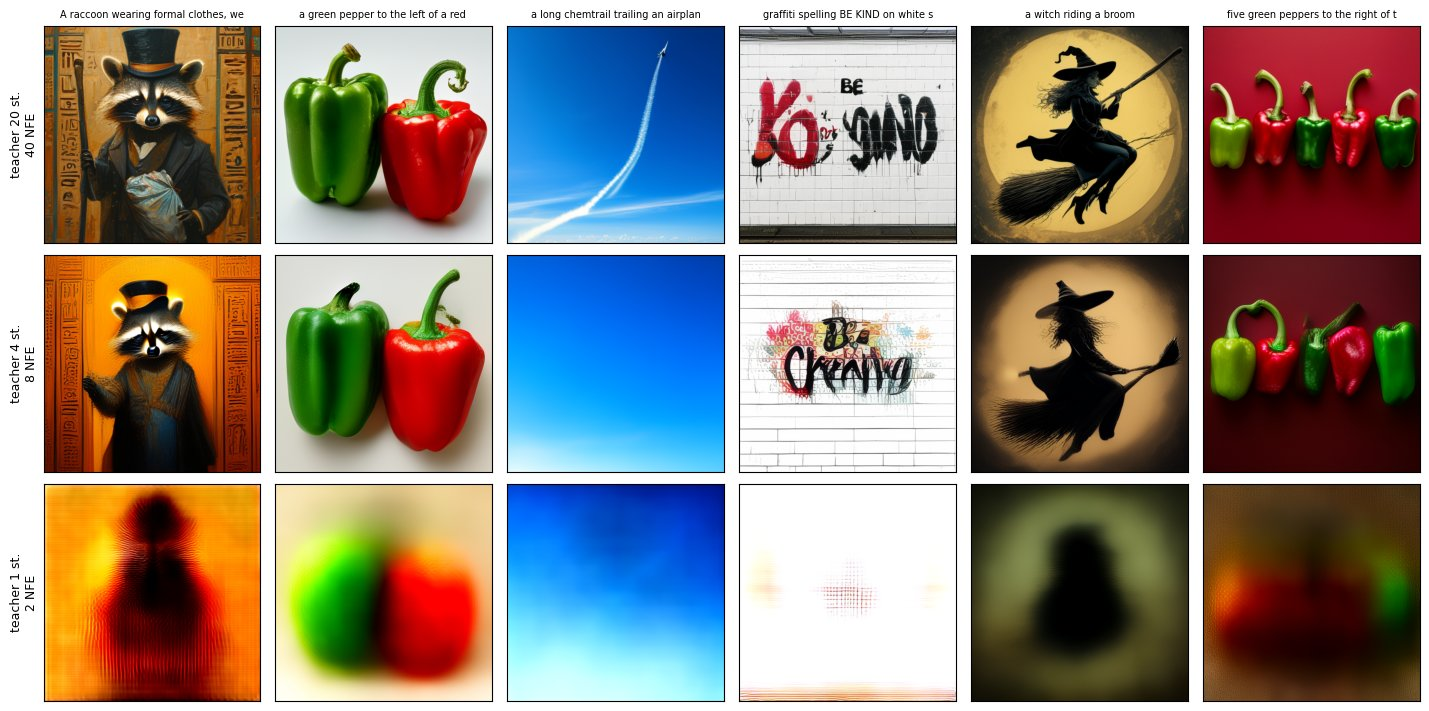

In [10]:
EVAL_IDX = torch.arange(len(TRAIN_PROMPTS), len(TEXT["prompts"]))
EVAL_COND = get_cond(EVAL_IDX)
EVAL_NOISE = latent_noise(len(EVAL_IDX), torch.Generator(device=DEVICE).manual_seed(1234))
SHORT = [p[:36] for p in TEXT["prompts"][len(TRAIN_PROMPTS):]]
OUT, SAMPLERS = {}, {}    # eval latents / sampling functions of every trained student

t0 = time.time()
REF = sample_teacher(EVAL_COND, EVAL_NOISE)
print(f"teacher, {TEACHER_STEPS} steps: {(time.time() - t0) / len(EVAL_IDX):.2f} s/image")
REF_FEW = sample_teacher(EVAL_COND, EVAL_NOISE, steps=STUDENT_NFE)
show_rows([REF, REF_FEW, sample_teacher(EVAL_COND, EVAL_NOISE, steps=1)],
          [f"teacher {TEACHER_STEPS} st.\n{2 * TEACHER_STEPS} NFE", f"teacher {STUDENT_NFE} st.\n{2 * STUDENT_NFE} NFE",
           "teacher 1 st.\n2 NFE"], SHORT)

### Synthetic dataset

CM, LADD and PDD need samples $x_0$: CM and PDD noise them to get points on the teacher's marginals $p_t$, and LADD uses them as "real" images. As in LADD (and our SD3 experiments), we use **teacher samples** rather than real images, which are free, perfectly aligned with the prompts, and exactly the distribution we want to match. DMD is data-free and only needs prompts.

With `USE_HF_DATA` they come from the HF dataset (Sana's default 20-step sampler, CFG 4.5); otherwise the cell below samples them with our Euler sampler and caches them.

teacher dataset: (2048, 32, 16, 16)


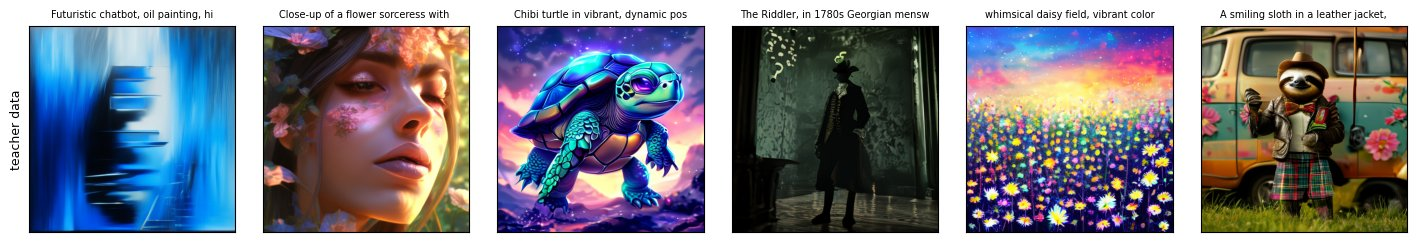

In [11]:
data_path = f"{CACHE_DIR}/teacher_data_n{len(TRAIN_PROMPTS)}_s{TEACHER_STEPS}.pt"
if USE_HF_DATA:
    pass                                   # DATA was loaded from the HF dataset together with the embeddings
elif os.path.exists(data_path):
    DATA = torch.load(data_path)
else:
    gen, lats, t0, bs = torch.Generator(device=DEVICE).manual_seed(SEED), [], time.time(), 16
    for i in range(0, len(TRAIN_PROMPTS), bs):
        idx = torch.arange(i, min(i + bs, len(TRAIN_PROMPTS)))
        lats.append(sample_teacher(get_cond(idx), latent_noise(len(idx), gen)).half().cpu())
        if i == 0:
            print(f"first batch: {time.time() - t0:.0f}s -> ETA {(time.time() - t0) * len(TRAIN_PROMPTS) / bs / 60:.1f} min")
    DATA = dict(lat=torch.cat(lats), prompt_idx=torch.arange(len(TRAIN_PROMPTS)))
    torch.save(DATA, data_path)
print("teacher dataset:", tuple(DATA["lat"].shape))
show_rows([DATA["lat"][:6].to(DEVICE).float()], ["teacher data"], [p[:36] for p in TRAIN_PROMPTS[:6]])

# 3. Consistency Distillation (multistep / phased CM)

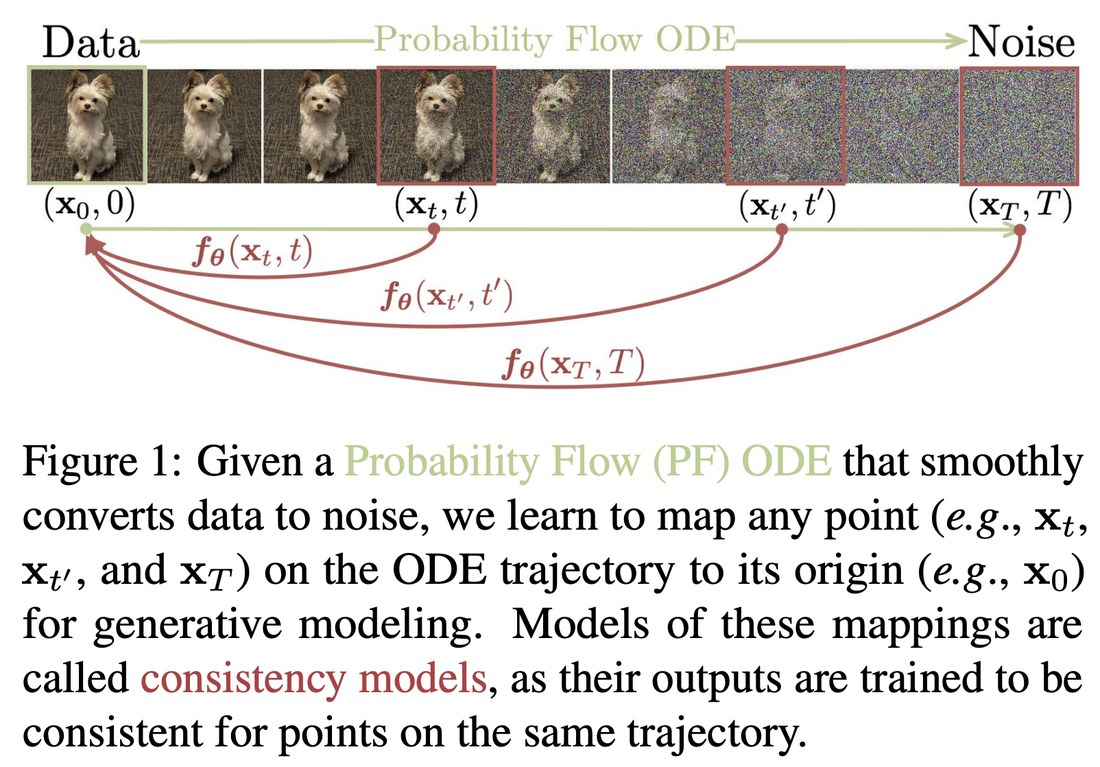

*Consistency models: every point of a PF-ODE trajectory is mapped to its origin (Song et al., 2023).*

A **consistency function** maps every point of a PF-ODE trajectory to the same endpoint. For a few-step generator we use the multistep ("phased") variant: split $[0,1]$ into $K$ phases with boundaries $1=s_0>s_1>\dots>s_K=0$ (the student's sampling times). Inside phase $p$ the student maps $x_t$ to the **end of its own phase**:

$$f_\theta(x_t,t)=x_t+(s_{p+1}-t)\,v_\theta(x_t,t).$$

The boundary condition $f_\theta(x_{s_{p+1}},s_{p+1})=x_{s_{p+1}}$ then holds by construction.

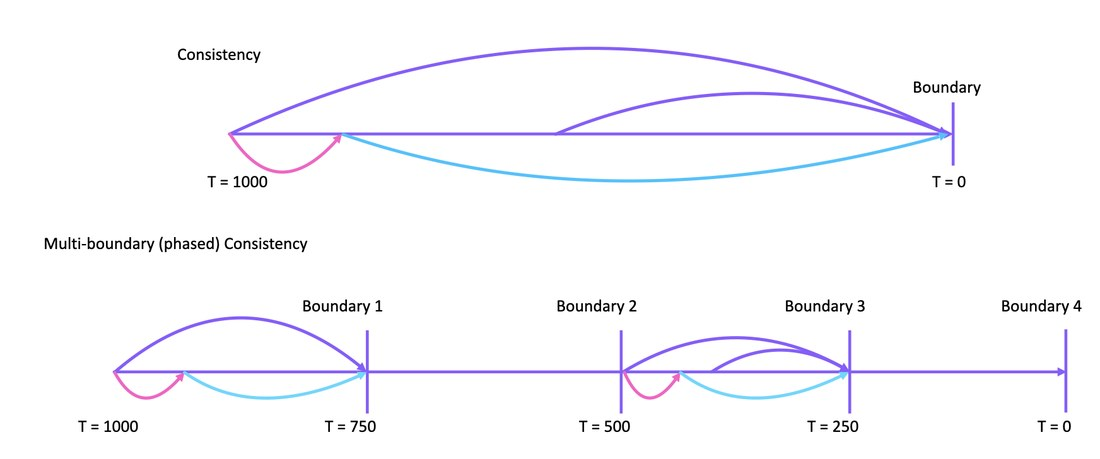

*Single-boundary vs multi-boundary (phased) consistency: pink = one teacher ODE step, cyan = the stop-grad target jump, purple = the student's jump to the phase boundary.*

**Consistency distillation loss**, using a fine grid $t_j$ (``n_fine`` teacher steps over all phases) and one teacher Euler step with CFG:

$$\hat x_{t_{j+1}} = x_{t_j} + (t_{j+1}-t_j)\,v^w_\text{teacher}(x_{t_j},t_j),\qquad
\mathcal L=\big\|f_\theta(x_{t_j},t_j)-\operatorname{sg}\,f_{\theta}(\hat x_{t_{j+1}},t_{j+1})\big\|^2 .$$

* The target network is the student itself with a stop-gradient (EMA decay 0, as in iCT/sCM and our SD3 code).
* Self-consistency propagates from the phase end backwards, one teacher step per "link". Fewer teacher steps per phase means faster propagation but a less accurate teacher ODE. That is the `n_fine` knob.
* Sampling: $K$ deterministic Euler jumps $s_p\to s_{p+1}$. The noise→image map stays close to the teacher's.

In [12]:
def cm_loss(student, teacher, x0, cond, boundaries, fine_grid):
    """Multistep consistency distillation.
    student/teacher: callables (x, t, cond) -> velocity (teacher already has CFG baked in).
    boundaries: K+1 times 1 = s_0 > ... > s_K = 0;  fine_grid: M+1 times containing the boundaries (M % K == 0)."""
    b, dev = x0.shape[0], x0.device
    K, M = len(boundaries) - 1, len(fine_grid) - 1
    per = M // K                                                             # teacher steps per phase
    # ========== YOUR CODE: consistency loss ==========
    # HINT: 1) phase p ~ U{0..K-1}, fine index j inside it: j = p*per + U{0..per-1};  t, t_next, t_b = fine_grid[j], fine_grid[j+1], boundaries[p+1]
    # HINT: 2) x_t = add_noise(x0, eps, t);  ONE teacher Euler step x_t -> x_next  (no grad)
    # HINT: 3) target = Euler jump x_next -> t_b with the student (no grad);  pred = Euler jump x_t -> t_b with the student
    phase = torch.randint(0, K, (b,), device=dev)
    j = phase * per + torch.randint(0, per, (b,), device=dev)
    t, t_next, t_b = fine_grid[j], fine_grid[j + 1], boundaries[phase + 1]
    x_t = add_noise(x0, torch.randn_like(x0), t)
    with torch.no_grad():
        x_next = euler(x_t, teacher(x_t, t, cond), t, t_next)                # one teacher ODE step
        target = euler(x_next, student(x_next, t_next, cond), t_next, t_b)   # stop-grad self-target
    pred = euler(x_t, student(x_t, t, cond), t, t_b)                         # f_theta(x_t, t)
    loss = F.mse_loss(pred, target)
    # ========== END OF YOUR CODE ==========
    return loss

In [13]:
# unit test: a perfect student on straight trajectories has zero loss, a wrong one does not
x0, oracle, _ = toy_problem()
bnd, fine = make_grid(4, device=DEVICE), make_grid(16, device=DEVICE)
assert cm_loss(oracle, oracle, x0, None, bnd, fine).item() < 1e-8, "perfect student must have zero loss"
assert cm_loss(lambda x, t, c: 1.1 * oracle(x, t), oracle, x0, None, bnd, fine).item() > 1e-6
print("CM tests passed ✓")

CM tests passed ✓


CM: 26.4M trainable LoRA params


[CM]    93/4000 | loss 0.0017 | 3.07 it/s | ETA 4.5 min


[CM]   185/4000 | loss 0.0014 | 3.06 it/s | ETA 4.0 min


[CM]   279/4000 | loss 0.0012 | 3.08 it/s | ETA 3.5 min


[CM]   374/4000 | loss 0.0011 | 3.10 it/s | ETA 3.0 min


[CM]   469/4000 | loss 0.0011 | 3.11 it/s | ETA 2.5 min


[CM]   560/4000 | loss 0.0011 | 3.09 it/s | ETA 2.0 min


[CM]   654/4000 | loss 0.0010 | 3.10 it/s | ETA 1.5 min


[CM]   749/4000 | loss 0.0010 | 3.10 it/s | ETA 1.0 min


[CM]   844/4000 | loss 0.0010 | 3.11 it/s | ETA 0.5 min


[CM] time budget of 5 min reached after 933 iterations


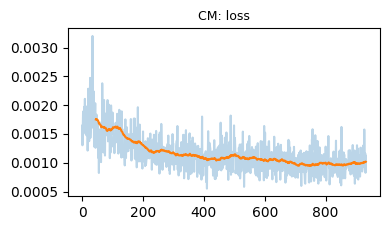

In [14]:
def train_cm(iters, batch, lr=1e-4, nfe=STUDENT_NFE, n_fine=None):
    n_fine = n_fine or 4 * nfe                    # 4 teacher ODE steps per phase
    assert n_fine % nfe == 0
    params = add_lora("cm")
    print(f"CM: {n_params(params) / 1e6:.1f}M trainable LoRA params")
    opt, scaler = adamw(params, lr), new_scaler()
    bnd, fine = make_grid(nfe), make_grid(n_fine)
    student = lambda x, t, c: velocity(x, t, c, "cm")
    meter = Meter("CM", iters)
    for it in range(iters):
        if meter.done():
            break
        x0, cond = data_batch(batch)
        loss = cm_loss(student, teacher_v, x0, cond, bnd, fine)
        opt_step(loss, opt, scaler, params)
        meter.log(it, loss=loss.item())
    return meter


meter = train_cm(P["iters"]["cm"], P["batch"])
meter.plot()
save_adapter("cm")

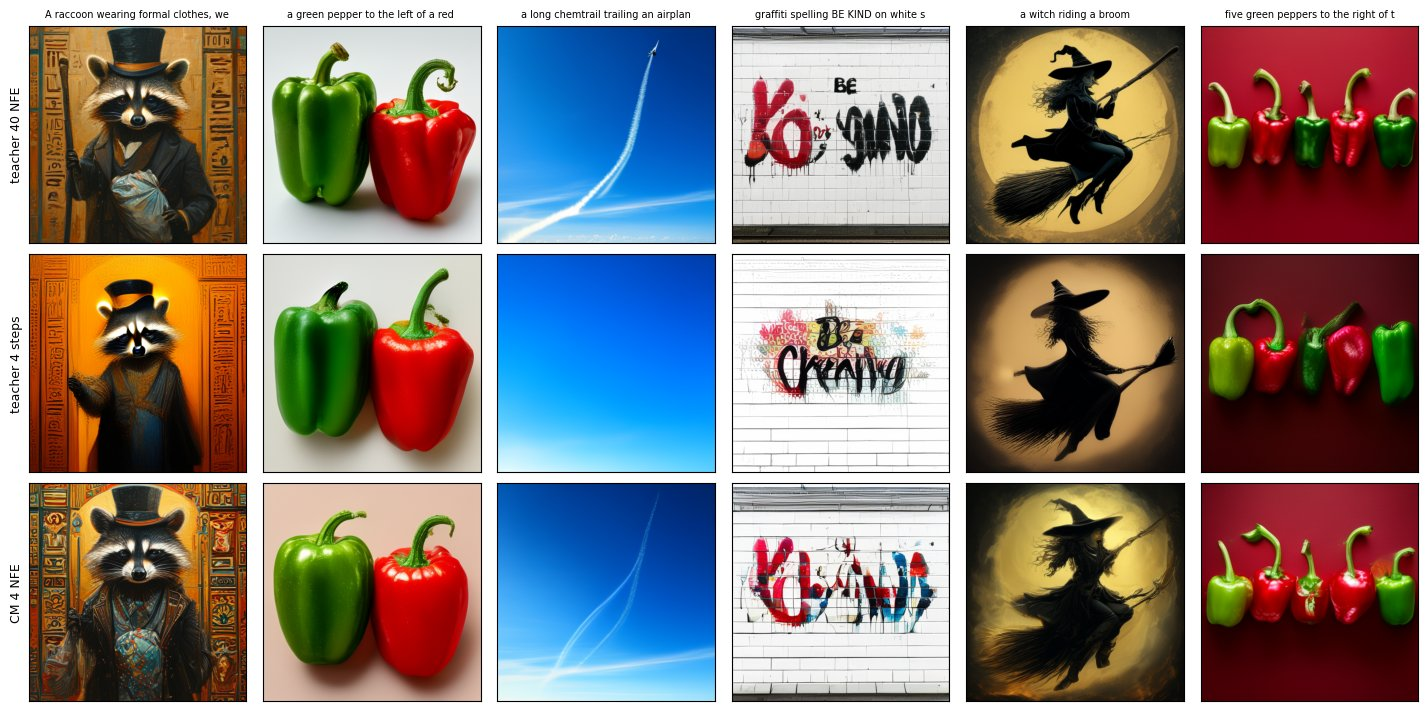

In [15]:
SAMPLERS["CM"] = lambda c, z: sample_student("cm", c, z, nfe=STUDENT_NFE, mode="ode")
OUT["CM"] = SAMPLERS["CM"](EVAL_COND, EVAL_NOISE)
show_rows([REF, REF_FEW, OUT["CM"]], ["teacher 40 NFE", f"teacher {STUDENT_NFE} steps", f"CM {STUDENT_NFE} NFE"], SHORT)

# 4. LADD: Latent Adversarial Diffusion Distillation

ADD used a DINOv2 discriminator in **pixel** space, which means decoding latents every step and is expensive. **LADD** builds the discriminator from the **frozen teacher** itself: re-noise the student's output, run the teacher backbone, and put small trainable heads on the token features of several blocks.

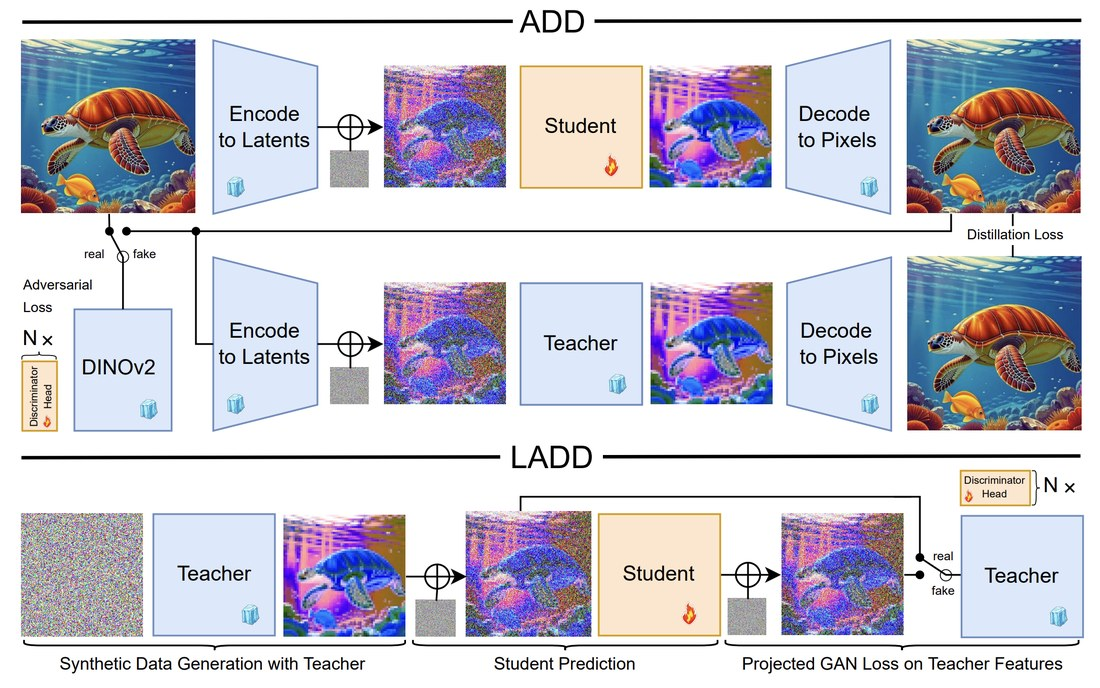

*ADD (top) vs LADD (bottom): synthetic data from the teacher, student prediction, projected GAN loss on the teacher's features (Sauer et al., 2024).*

$$\hat x_0=x_t-t\,v_\theta(x_t,t),\qquad \hat x_{t_r}=(1-t_r)\,\hat x_0+t_r\,\varepsilon,\qquad t_r\sim\text{logit-normal}(m,s)$$

$$\mathcal L_G=-\,\mathbb E\,D(\hat x_{t_r},t_r,c),\qquad
\mathcal L_D=\mathbb E\,[1-D(x^\text{real}_{t_r})]_+ + \mathbb E\,[1+D(\hat x_{t_r})]_+ \quad(\text{hinge}).$$

* There is **no regression loss at all**: the student only has to fool $D$. The "real" images are teacher samples (LADD found synthetic data works better than real data).
* The re-noising level $t_r$ decides what $D$ looks at: high $t_r$ → global layout, low $t_r$ → texture and detail. LADD biases it toward higher noise; it is the `t_mean` knob.
* The backbone is frozen, so the discriminator is cheap. We even **stop the forward pass after the last tapped block** (`_StopForward`).
* The generator's input is a noised teacher sample at one of the student's `STUDENT_NFE` timesteps. Sampling predicts $x_0$ and re-noises it with fresh noise (ADD-style).

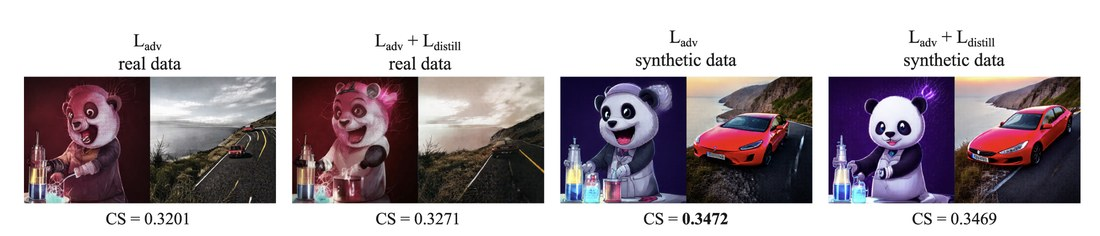

*Synthetic teacher data beats real data, and with it the distillation loss is unnecessary (LADD paper).*

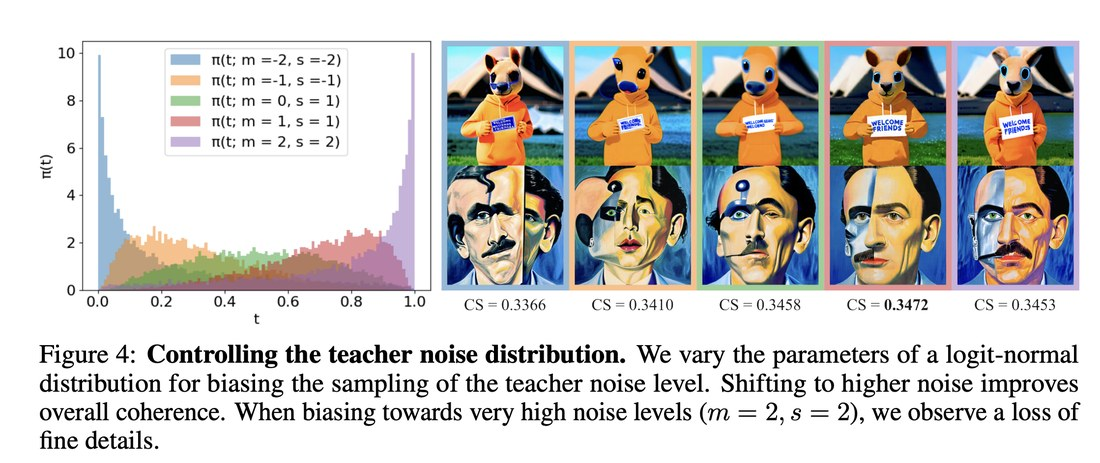

*The discriminator's noise distribution: biasing toward higher noise (m = 1, s = 1, our default `t_mean=1.0`) improves coherence; too high loses detail (LADD paper).*

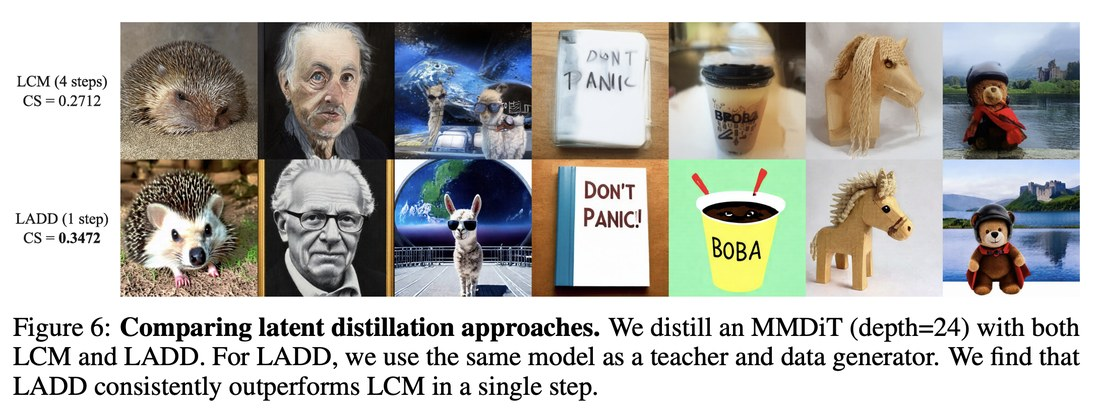

*LADD in 1 step vs LCM in 4 steps on the same MMDiT teacher (LADD paper). Compare with our CM and LADD students in section 7.*

In [16]:
class _StopForward(Exception):
    pass


class DiscHead(nn.Module):
    """Light conv head on one block's token features -> patch-wise real/fake logits."""
    def __init__(self, dim, hidden=256):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.net = nn.Sequential(nn.Conv2d(dim, hidden, 3, padding=1), nn.GroupNorm(32, hidden), nn.SiLU(),
                                 nn.Conv2d(hidden, 1, 1))

    def forward(self, tokens, hw):
        x = self.norm(tokens.float())                                # (B, h*w, D)
        x = x.transpose(1, 2).reshape(x.shape[0], -1, hw, hw)        # (B, D, h, w)
        return self.net(x)                                           # (B, 1, h, w)


class LADDDiscriminator(nn.Module):
    """FROZEN TEACHER (all adapters off) as a feature extractor + trainable heads on several blocks (forward hooks)."""
    def __init__(self, layer_ids, hidden=256):
        super().__init__()
        self.layer_ids = sorted(layer_ids)
        dim = transformer.config.num_attention_heads * transformer.config.attention_head_dim
        self.hw = LAT_HW // transformer.config.patch_size
        self.heads = nn.ModuleList([DiscHead(dim, hidden) for _ in self.layer_ids])
        self._feats, self._on = {}, False
        self._hooks = [transformer.transformer_blocks[i].register_forward_hook(self._make_hook(i))
                       for i in self.layer_ids]

    def _make_hook(self, i):
        def hook(module, inputs, output):
            if self._on:
                self._feats[i] = output[0] if isinstance(output, tuple) else output
                if i == self.layer_ids[-1]:
                    raise _StopForward          # the remaining blocks are not needed
        return hook

    def forward(self, x, t, cond, backbone_grad=True):
        """backbone_grad=True: gradients flow back to x (generator step); False: only the heads are trained."""
        self._feats, self._on = {}, True
        try:
            with torch.set_grad_enabled(backbone_grad and torch.is_grad_enabled()):
                velocity(x, t, cond, adapter=None)
        except _StopForward:
            pass
        finally:
            self._on = False
        logits = [head(self._feats[i], self.hw) for head, i in zip(self.heads, self.layer_ids)]
        return torch.cat([l.flatten(1) for l in logits], dim=1)     # (B, n_heads * h * w)

    def remove_hooks(self):
        for h in self._hooks:
            h.remove()


def ladd_generator_loss(student, disc, x0_data, cond, student_ts, t_mean=1.0, t_std=1.0):
    """Returns (hinge generator loss, detached x0_hat, re-noising times t_r)."""
    b, dev = x0_data.shape[0], x0_data.device
    # ========== YOUR CODE: LADD generator loss ==========
    # HINT: t ~ one of student_ts per sample; x_t = noised teacher sample; x0_hat = x0_from_v(x_t, student(...), t)
    # HINT: t_r = sigmoid(N(t_mean, t_std)); re-noise x0_hat to t_r (keep the graph!) and score it: loss = -D(...).mean()
    t = student_ts[torch.randint(0, len(student_ts), (b,), device=dev)]
    x_t = add_noise(x0_data, torch.randn_like(x0_data), t)
    x0_hat = x0_from_v(x_t, student(x_t, t, cond), t)
    t_r = torch.sigmoid(torch.randn(b, device=dev) * t_std + t_mean)
    x_r = add_noise(x0_hat, torch.randn_like(x0_hat), t_r)
    loss = -disc(x_r, t_r, cond).mean()
    # ========== END OF YOUR CODE ==========
    return loss, x0_hat.detach(), t_r


def ladd_discriminator_loss(disc, x0_fake, x0_real, cond, t_r):
    """Hinge loss. Fake and real latents are re-noised to the SAME t_r and scored in one batched pass."""
    # ========== YOUR CODE: LADD discriminator loss ==========
    # HINT: concatenate re-noised fake and real, call disc(..., backbone_grad=False), split logits with .chunk(2)
    x = torch.cat([add_noise(x0_fake, torch.randn_like(x0_fake), t_r),
                   add_noise(x0_real, torch.randn_like(x0_real), t_r)])
    logits_fake, logits_real = disc(x, torch.cat([t_r, t_r]), cat_cond(cond, cond), backbone_grad=False).chunk(2)
    loss = F.relu(1 - logits_real).mean() + F.relu(1 + logits_fake).mean()
    # ========== END OF YOUR CODE ==========
    return loss

In [17]:
x0, oracle, _ = toy_problem()


class _LinearDisc(nn.Module):        # logit = mean(x)
    def forward(self, x, t, cond, backbone_grad=True):
        return x.flatten(1).mean(1, keepdim=True)


class _PerfectDisc(nn.Module):       # -2 for the first half (fake), +2 for the second half (real)
    def forward(self, x, t, cond, backbone_grad=True):
        b = x.shape[0] // 2
        return torch.cat([-2 * torch.ones(b, 1), 2 * torch.ones(b, 1)]).to(x.device)


theta = torch.zeros_like(x0, requires_grad=True)
student = lambda x, t, c: (x - theta) / bc(t, x)                         # x0_hat == theta for any input
loss_g, x0_hat, t_r = ladd_generator_loss(student, _LinearDisc(), x0, None, make_grid(4, device=DEVICE)[:-1])
loss_g.backward()
assert torch.allclose(x0_hat, theta.detach(), atol=1e-5), "x0_hat must be the student's clean prediction"
assert (theta.grad < 0).all(), "the generator must push its samples towards higher logits"
assert ladd_discriminator_loss(_PerfectDisc(), x0, x0, None, t_r).item() == 0.0
print("LADD tests passed ✓")

LADD tests passed ✓


/home/jovyan/novitskiy/ddw_venv/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


LADD: 26.4M LoRA params, 10.6M head params, features from blocks [6, 13, 20, 27]


[LADD]    84/3000 | loss_g 0.1912 | loss_d 1.6195 | 2.78 it/s | ETA 4.5 min


[LADD]   170/3000 | loss_g 0.0898 | loss_d 1.8520 | 2.81 it/s | ETA 4.0 min


[LADD]   256/3000 | loss_g 0.0751 | loss_d 1.8605 | 2.83 it/s | ETA 3.5 min


[LADD]   342/3000 | loss_g 0.0542 | loss_d 1.8802 | 2.84 it/s | ETA 3.0 min


... (2 outputs left out)

[LADD]   599/3000 | loss_g 0.0397 | loss_d 1.9192 | 2.84 it/s | ETA 1.5 min


[LADD]   685/3000 | loss_g 0.0398 | loss_d 1.9319 | 2.84 it/s | ETA 1.0 min


[LADD]   771/3000 | loss_g 0.0461 | loss_d 1.9371 | 2.84 it/s | ETA 0.5 min


[LADD] time budget of 5 min reached after 853 iterations


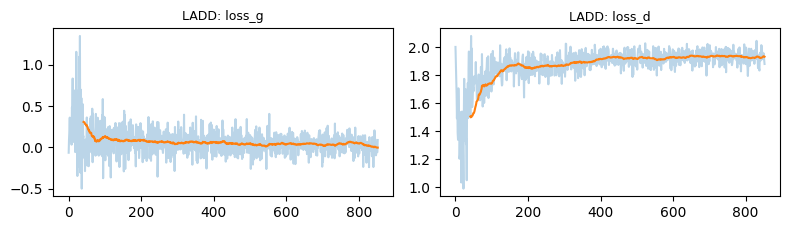

In [18]:
def train_ladd(iters, batch, lr_g=1e-4, lr_d=1e-4, nfe=STUDENT_NFE, layers=None, t_mean=1.0, t_std=1.0):
    nb = len(transformer.transformer_blocks)
    layers = layers or [nb // 4 - 1, nb // 2 - 1, 3 * nb // 4 - 1, nb - 1]
    params = add_lora("ladd")
    disc = LADDDiscriminator(layers).to(DEVICE)
    print(f"LADD: {n_params(params) / 1e6:.1f}M LoRA params, {n_params(disc.parameters()) / 1e6:.1f}M head params, "
          f"features from blocks {layers}")
    # beta1 = 0: momentum makes min-max games oscillate
    opt_g, opt_d = adamw(params, lr_g, betas=(0.0, 0.99)), adamw(disc.parameters(), lr_d, betas=(0.0, 0.99))
    sc_g, sc_d = new_scaler(), new_scaler()
    ts = make_grid(nfe)[:-1]                       # the student's timesteps 1 = t_0 > ... > t_{K-1}
    student = lambda x, t, c: velocity(x, t, c, "ladd")
    meter = Meter("LADD", iters)
    try:
        for it in range(iters):
            if meter.done():
                break
            x0, cond = data_batch(batch)
            disc.requires_grad_(False)                         # G step: gradients only into the student
            loss_g, x0_hat, t_r = ladd_generator_loss(student, disc, x0, cond, ts, t_mean, t_std)
            opt_step(loss_g, opt_g, sc_g, params)
            disc.requires_grad_(True)                          # D step: only the heads (backbone is frozen)
            loss_d = ladd_discriminator_loss(disc, x0_hat, x0, cond, t_r)
            opt_step(loss_d, opt_d, sc_d, list(disc.parameters()))
            meter.log(it, loss_g=loss_g.item(), loss_d=loss_d.item())
    finally:
        disc.remove_hooks()
    return meter


meter = train_ladd(P["iters"]["ladd"], P["batch"])
meter.plot()
save_adapter("ladd")

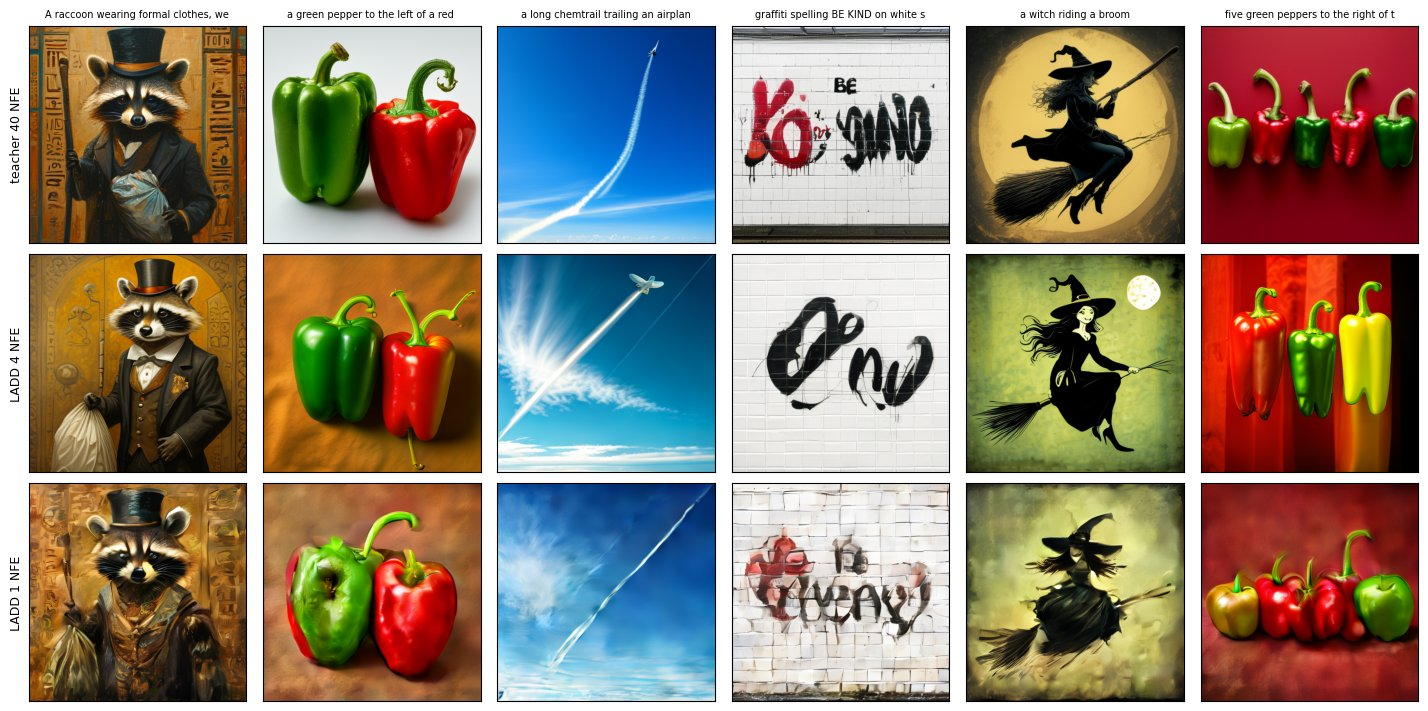

In [19]:
SAMPLERS["LADD"] = lambda c, z: sample_student("ladd", c, z, nfe=STUDENT_NFE, mode="renoise")
OUT["LADD"] = SAMPLERS["LADD"](EVAL_COND, EVAL_NOISE)
show_rows([REF, OUT["LADD"], sample_student("ladd", EVAL_COND, EVAL_NOISE, nfe=1)],
          ["teacher 40 NFE", f"LADD {STUDENT_NFE} NFE", "LADD 1 NFE"], SHORT)

# 5. DMD: Distribution Matching Distillation (DMD2-style)

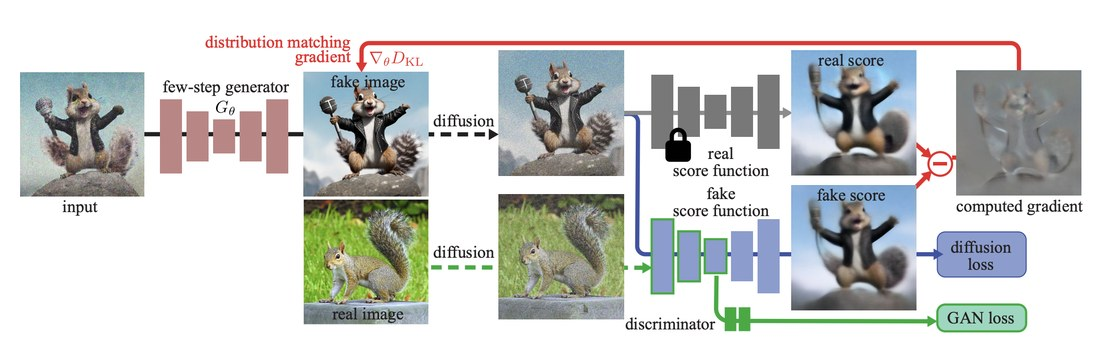

*DMD/DMD2: the distribution-matching gradient is the difference between the real (frozen teacher) and fake (online) scores at a re-noised generator sample. DMD2 optionally adds a GAN loss on the fake model's features (Yin et al., 2024).*

Minimize the reverse KL between the student's distribution $p_\theta$ and the teacher's, at all noise levels:

$$\nabla_\theta \mathrm{KL}\big(p_{\theta,t}\,\|\,p_{\text{real},t}\big)=\mathbb E\Big[\big(s_\text{fake}(x_t)-s_\text{real}(x_t)\big)^\top\tfrac{\partial x_t}{\partial\theta}\Big],\qquad x_t=(1-t)\,G_\theta(z)+t\,\varepsilon .$$

* $s_\text{real}$ is the **teacher with CFG**. $s_\text{fake}$ is a second network (here a LoRA initialized from the teacher), trained **online** with the plain flow-matching loss on the student's samples, so it always models the *current* $p_\theta$.
* In $x_0$-parameterization the score difference is $\propto \hat x_0^\text{fake}-\hat x_0^\text{real}$, normalized per sample by $\;w=\operatorname{mean}|\hat x_0-\hat x_0^\text{real}|$.
* Implementation trick: $\mathcal L=\tfrac12\|\hat x_0-\operatorname{sg}(\hat x_0-g)\|^2$ has $\nabla_{\hat x_0}\mathcal L=g$. The *value* of this "loss" means nothing, so instead we plot the DMD gradient itself on its own figure: the RMS of $g$, and the LoRA gradient norm it produces. $g$ should shrink as the fake score catches up with the student and the student approaches the teacher. Spikes or steady growth mean the fake model is lagging; then give it more updates per student step (`gen_every`, default 5 as in DMD2).
* DMD2 ingredients used here: **two time-scale updates** (5 fake-model updates per generator update, `gen_every=5`), **backward simulation** (the generator is trained on its *own* intermediate states, the same inputs it meets at inference), and no regression loss.
* Reverse KL is **mode-seeking**: sharp samples, but less diversity. Check this in section 7.

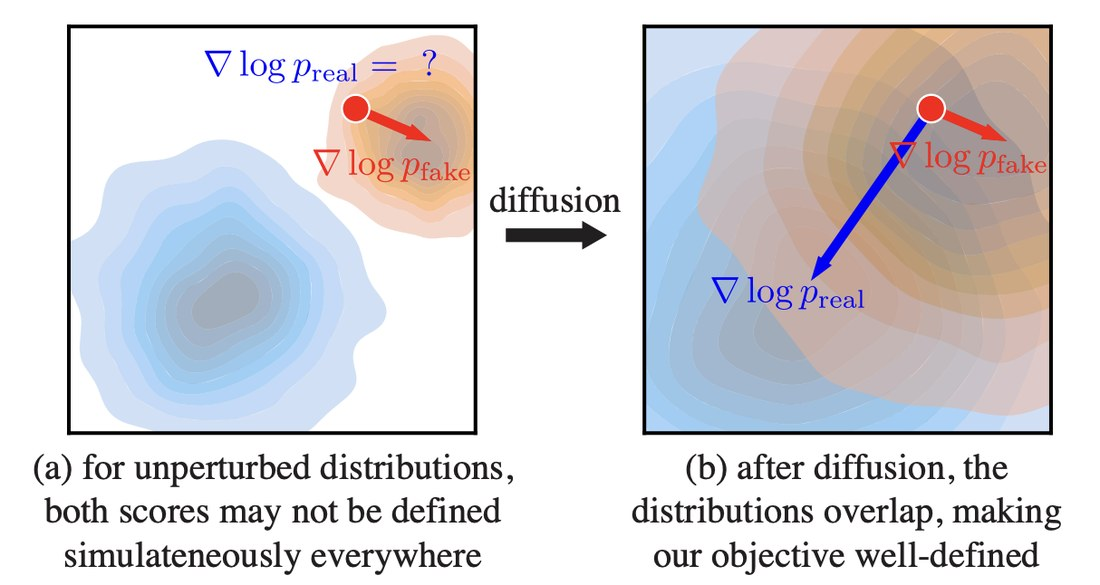

*Why the scores are taken at noised points: clean real and fake distributions may not overlap, so the KL gradient is undefined; after diffusion both scores exist everywhere (DMD paper).*

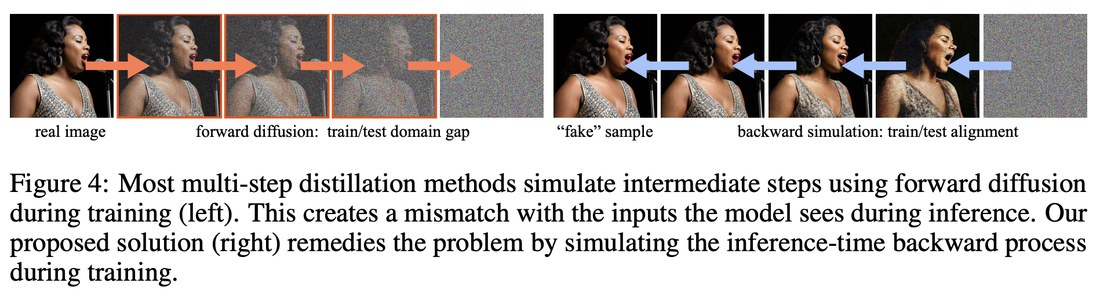

*Backward simulation (DMD2): train the multi-step generator on its own intermediate states instead of forward-noised real images. The simulation must use the same sampler as inference; here x0-prediction + re-noising (`DMD_MODE="renoise"`), as in our SD3 config.*

In [20]:
@torch.no_grad()
def backward_simulation(student, cond, ts, shape, mode="ode"):
    """Run the student's own k-step sampler from noise (no grad) and return the state it sees at step k.
    mode must match the sampler used at inference: 'ode' = Euler steps, 'renoise' = predict x0 and add fresh noise."""
    b = shape[0]
    x = torch.randn(shape, device=DEVICE)
    k = random.randint(0, len(ts) - 2)
    for i in range(k):
        v = student(x, as_batch(ts[i], b), cond)
        if mode == "ode":
            x = euler(x, v, ts[i], ts[i + 1])
        else:
            x = add_noise(x0_from_v(x, v, ts[i]), torch.randn_like(x), ts[i + 1])
    return x, as_batch(ts[k], b)


def dmd_generator_loss(student, teacher, fake, x_in, t_in, cond, t_min=0.02, t_max=0.98):
    """Distribution-matching gradient as an MSE to a stop-grad target. Returns (loss, detached x0_hat, DMD gradient g)."""
    b, dev = x_in.shape[0], x_in.device
    # ========== YOUR CODE: DMD generator loss ==========
    # HINT: x0_hat = student's clean prediction from (x_in, t_in)  (with grad)
    # HINT: t = shift_t(U[t_min, t_max]); x_t = re-noised x0_hat.detach();  x0_real / x0_fake from teacher / fake at (x_t, t)
    # HINT: grad = (x0_fake - x0_real) / mean|x0_hat - x0_real| (per sample);  loss = 0.5 * mse(x0_hat, sg(x0_hat - grad))
    x0_hat = x0_from_v(x_in, student(x_in, t_in, cond), t_in)
    t = shift_t(t_min + (t_max - t_min) * torch.rand(b, device=dev))
    x_t = add_noise(x0_hat.detach(), torch.randn_like(x0_hat), t)
    with torch.no_grad():
        x0_real = x0_from_v(x_t, teacher(x_t, t, cond), t)
        x0_fake = x0_from_v(x_t, fake(x_t, t, cond), t)
        weight = (x0_hat - x0_real).abs().mean(dim=(1, 2, 3), keepdim=True).clamp_min(1e-6)
        grad = (x0_fake - x0_real) / weight
    loss = 0.5 * F.mse_loss(x0_hat, (x0_hat - grad).detach())
    # ========== END OF YOUR CODE ==========
    return loss, x0_hat.detach(), grad


def dmd_fake_loss(fake, x0_gen, cond):
    """Keep the 'fake' model a flow-matching model of the CURRENT student distribution."""
    b, dev = x0_gen.shape[0], x0_gen.device
    # ========== YOUR CODE: fake score loss ==========
    # HINT: the standard flow-matching loss on student samples: t = shift_t(U[0,1]), target velocity = eps - x0_gen
    t = shift_t(torch.rand(b, device=dev))
    eps = torch.randn_like(x0_gen)
    loss = F.mse_loss(fake(add_noise(x0_gen, eps, t), t, cond), eps - x0_gen)
    # ========== END OF YOUR CODE ==========
    return loss

In [21]:
x0, teacher_oracle, x0_star = toy_problem()
theta = torch.zeros_like(x0, requires_grad=True)
student = lambda x, t, c: (x - theta) / bc(t, x)                 # the student always outputs x0_hat = theta
x_in, t_in = torch.randn_like(x0), torch.ones(x0.shape[0], device=DEVICE)
# 1) fake == real  ->  zero gradient
loss, _, _ = dmd_generator_loss(student, teacher_oracle, teacher_oracle, x_in, t_in, None)
assert loss.item() < 1e-10, "no gradient when the student distribution already matches"
# 2) with a perfect fake model of the student (point mass at theta), the update must move theta towards x0*
loss, _, _ = dmd_generator_loss(student, teacher_oracle, make_oracle(theta.detach()), x_in, t_in, None)
loss.backward()
cos = F.cosine_similarity(-theta.grad.flatten(), (x0_star - theta.detach()).flatten(), dim=0)
assert cos > 0.99, f"DMD gradient points the wrong way (cos={cos:.3f})"
# 3) the exact velocity field of the generated distribution has (almost) zero fake loss
assert dmd_fake_loss(make_oracle(x0_star), x0, None).item() < 1e-6
print("DMD tests passed ✓")

DMD tests passed ✓


DMD: 105.4M generator + 105.4M fake-score LoRA params


[DMD]    50/6000 | loss_fake 0.1835 | student_grad_norm 0.0065 | dmd_grad_rms 1.0632 | 1.66 it/s | ETA 29.5 min


[DMD]   103/6000 | loss_fake 0.1623 | student_grad_norm 0.0085 | dmd_grad_rms 1.1583 | 1.70 it/s | ETA 29.0 min


[DMD]   156/6000 | loss_fake 0.1533 | student_grad_norm 0.0079 | dmd_grad_rms 1.1780 | 1.72 it/s | ETA 28.5 min


[DMD]   207/6000 | loss_fake 0.1595 | student_grad_norm 0.0102 | dmd_grad_rms 1.2166 | 1.71 it/s | ETA 28.0 min


[DMD]   261/6000 | loss_fake 0.1383 | student_grad_norm 0.0102 | dmd_grad_rms 1.2477 | 1.73 it/s | ETA 27.5 min


... (51 outputs left out)

[DMD]  2978/6000 | loss_fake 0.3449 | student_grad_norm 0.0350 | dmd_grad_rms 1.0643 | 1.72 it/s | ETA 1.2 min


[DMD]  3027/6000 | loss_fake 0.3330 | student_grad_norm 0.0356 | dmd_grad_rms 1.0172 | 1.72 it/s | ETA 0.7 min


[DMD]  3077/6000 | loss_fake 0.3547 | student_grad_norm 0.0428 | dmd_grad_rms 1.0737 | 1.72 it/s | ETA 0.2 min


[DMD] time budget of 30 min reached after 3101 iterations


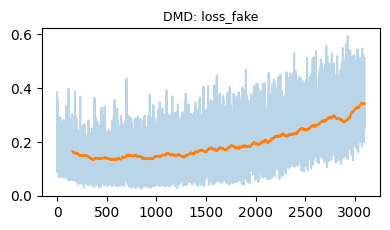

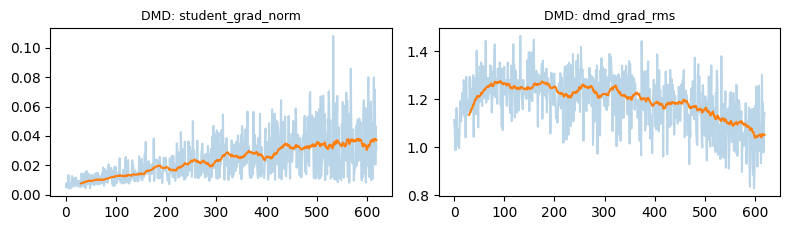

In [22]:
# Defaults = our SD3 DMD2 config that works (sd3_dmd2_v1): renoise backward simulation (stochastic_sampling: true),
# LR 1e-5 for generator and fake score, betas (0.9, 0.95), LoRA r=128, 5 fake updates per generator update.
# That run used batch 64 for 3000 iterations (600 generator updates): DMD needs far more steps than CM/PDD.
DMD_MODE = "renoise"  # backward simulation AND inference sampler


def train_dmd(iters, batch, lr_g=1e-5, lr_f=1e-5, nfe=STUDENT_NFE, gen_every=5, betas=(0.9, 0.95), mode=DMD_MODE,
              rank=128, init_from=None, minutes="default"):
    """Every iteration updates the fake score; every `gen_every`-th iteration also updates the student (DMD2: 5:1).
    init_from: name of an already trained adapter (e.g. "cm") to start the student from instead of the teacher."""
    p_g, p_f = add_lora("dmd", rank), add_lora("dmd_fake", rank)
    if init_from is not None:
        set_peft_model_state_dict(transformer, get_peft_model_state_dict(transformer, adapter_name=init_from),
                                  adapter_name="dmd")
        HUB.sync()
        print(f"DMD student initialised from the '{init_from}' adapter")
    print(f"DMD: {n_params(p_g) / 1e6:.1f}M generator + {n_params(p_f) / 1e6:.1f}M fake-score LoRA params")
    opt_g, opt_f, sc_g, sc_f = adamw(p_g, lr_g, betas), adamw(p_f, lr_f, betas), new_scaler(), new_scaler()
    ts = make_grid(nfe)
    student = lambda x, t, c: velocity(x, t, c, "dmd")
    fake = lambda x, t, c: velocity(x, t, c, "dmd_fake")             # starts as the teacher WITHOUT CFG
    meter = Meter("DMD", iters, minutes=minutes)
    for it in range(iters):
        if meter.done():
            break
        cond = prompt_batch(batch)                                   # data-free: prompts only
        x_in, t_in = backward_simulation(student, cond, ts, (batch, LAT_C, LAT_HW, LAT_HW), mode)
        logs = {}
        if (it + 1) % gen_every == 0:                                # TTUR: gen_every fake updates per student update
            loss_g, x0_gen, g = dmd_generator_loss(student, teacher_v, fake, x_in, t_in, cond)
            logs["student_grad_norm"] = opt_step(loss_g, opt_g, sc_g, p_g)       # LoRA gradient norm (pre-clip)
            logs["dmd_grad_rms"] = g.pow(2).mean().sqrt().item()                 # RMS of g = (x0_fake - x0_real) / w
        else:
            with torch.no_grad():
                x0_gen = x0_from_v(x_in, student(x_in, t_in, cond), t_in)
        loss_f = dmd_fake_loss(fake, x0_gen, cond)
        opt_step(loss_f, opt_f, sc_f, p_f)
        meter.log(it, loss_fake=loss_f.item(), **logs)
    return meter


# Our SD3 DMD2 config (sd3_dmd2_v1) that works: verified on Sana with batch 64 x 3000 iterations (~1 h on one H100):
# students become sharp only after ~1500+ iterations, so DMD gets its own, longer time budget.
DMD_MINUTES = 30      # None = run all P["iters"]["dmd"] iterations
DMD_BATCH = P["batch"]  # SD3 run: 64 (16 per GPU x 4); use the largest batch your GPU fits
meter = train_dmd(P["iters"]["dmd"], DMD_BATCH,
                  lr_g=1e-5, lr_f=1e-5, betas=(0.9, 0.95),   # optimizer / fake_optimizer
                  gen_every=5,                                 # generator_update_freq: 5 fake updates per student update
                  rank=128,                                    # lora.r = lora_alpha = 128
                  mode="renoise",                              # backward_sim + stochastic_sampling: true
                  minutes=DMD_MINUTES)
meter.plot(["loss_fake"])
meter.plot(["dmd_grad_rms", "student_grad_norm"])     # the DMD gradient on its own plot
save_adapter("dmd")

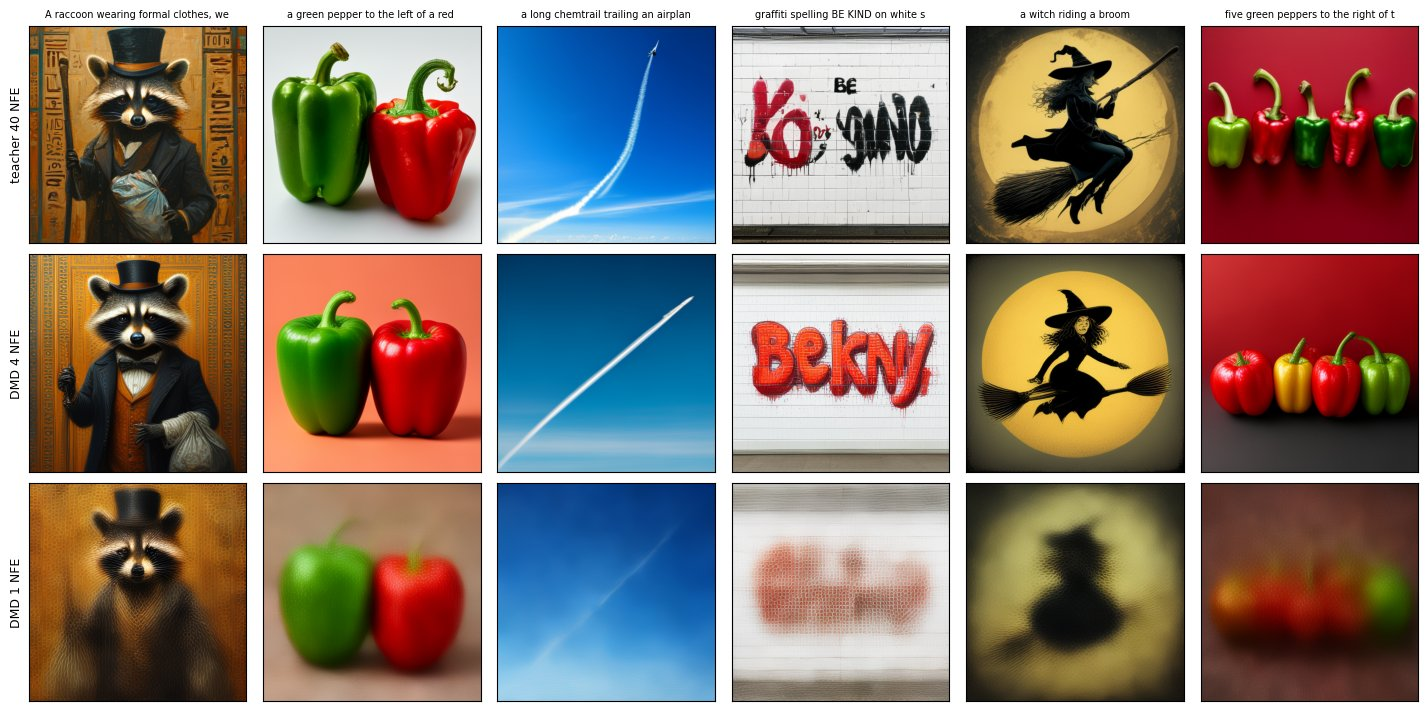

In [23]:
SAMPLERS["DMD"] = lambda c, z: sample_student("dmd", c, z, nfe=STUDENT_NFE, mode=DMD_MODE)
OUT["DMD"] = SAMPLERS["DMD"](EVAL_COND, EVAL_NOISE)
show_rows([REF, OUT["DMD"], sample_student("dmd", EVAL_COND, EVAL_NOISE, nfe=1)],
          ["teacher 40 NFE", f"DMD {STUDENT_NFE} NFE", "DMD 1 NFE"], SHORT)

# 6. PDD: Parallel Decoding Distillation

*Shaul, Liu, Vahdat, Berner (NVIDIA), "Parallel Decoding Distillation for Fast Image and Video Generation", 2026.* A trajectory method with **one regression loss**: no VSD, no GAN, no JVPs, single stage.

**Idea.** Fix a fine grid $1=t_0>t_1>\dots>t_N=0$ with $h_k=t_{k+1}-t_k$. (The paper runs time the other way, $t=0$ noise; we keep the SD3/Sana convention.) The exact trajectory satisfies $X_{k+1}=X_k+h_k\,u_k(X_k)$, where $u_k$ is the *mean* velocity over interval $k$. A **parallel decoder** predicts, from the single state $X_n$ in **one forward pass**, the velocities of the next $L$ intervals: $\bar u_\theta(k\mid X_n)\approx u_k(X_k)$ for $k=n,\dots,n+L-1$. This is like multi-token prediction in LLMs.

**Architecture.** The backbone is unchanged; only the final linear layer is repeated $N$ times, $\bar u_\theta(k\mid x_n)=W_k\,H_{t_n}(x_n)$, and every $W_k$ is initialized as the teacher's head. At init each block step is therefore one big teacher Euler step, which is our `GridHead`.

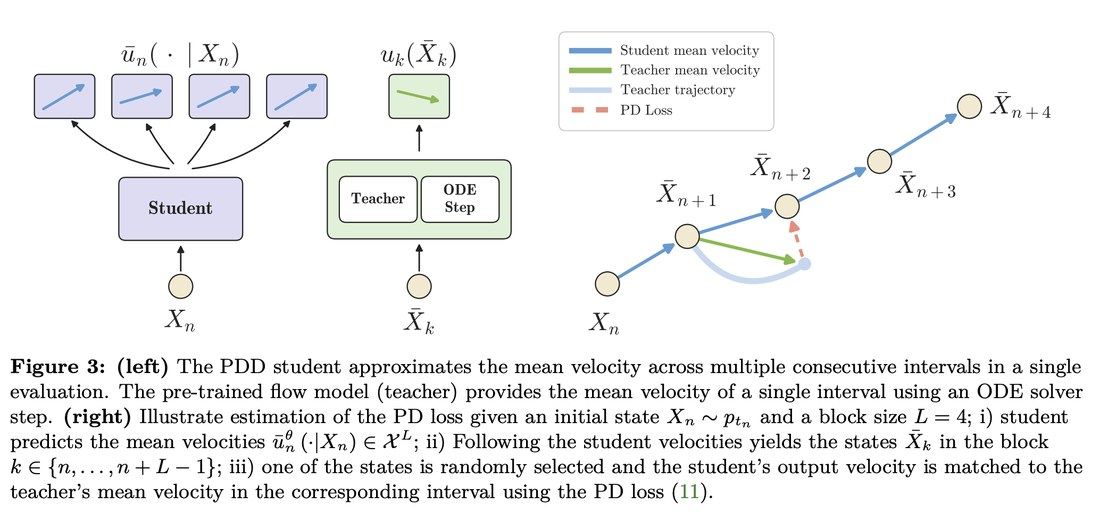

*PDD: from one state the student predicts L mean velocities at once (left); training rolls out the student's own velocities and matches each to one ODE step of the teacher at the reached state (right) (Shaul et al., 2026).*

**Loss (on-policy).** The student rolls out its own predictions inside the block,

$$\bar X_k = X_n+\sum_{l=n}^{k-1} h_l\,\bar u_\theta(l\mid X_n),\qquad
\mathcal L_\text{PDD}=\big\|\bar u_\theta(k\mid X_n)-\operatorname{sg}\,u^\text{teacher}_k(\bar X_k)\big\|^2 ,$$

where $u^\text{teacher}_k$ is **one Runge–Kutta step of the CFG teacher** at the student's state: Euler, $v^w_{t_k}(x)$, or midpoint, $v^w_{t_k+h_k/2}\big(x+\tfrac{h_k}{2}v^w_{t_k}(x)\big)$. Only head $k$ receives gradient.

**Proposition.** If the loss is zero, then $\bar X_k=X_k$ by induction: the student reproduces the teacher's discretized trajectory **exactly**, with $N/L$ NFE instead of $N$.

**Sampling.** $\bar X_{n+L}=X_n+\sum_{k=n}^{n+L-1}h_k\,\bar u_\theta(k\mid X_n)$ for $n=0,L,2L,\dots$, so NFE $=N/L$. One model serves any $L$ that is a multiple of `L_min` and at most `L_max`. By linearity the $L$ used heads can be **fused** into a single linear layer per block, so inference costs exactly the teacher architecture.

Paper settings, for reference: T2I/T2V use $N=256$ (Euler) or $128$ (midpoint) with a shifted grid, AdamW at constant LR 1e-5, batch 2048, and only **250–3k iterations**. Here we use $N=32$ and train exactly the block size we sample with, `L_min = L_max = N / STUDENT_NFE` (8 for 4 NFE), with midpoint targets. Lowering `L_min` makes one model serve several NFEs, at the cost of spreading the same training budget.

In [24]:
def pdd_rollout(x_n, u, n, k, h):
    """Student's own Euler rollout inside the block:  x_k = x_n + sum_{l=n}^{k-1} h_l * u_l.
    x_n: (B,C,H,W); u: (B,N,C,H,W) predicted velocities; n, k: (B,) grid indices; h: (N,) steps t_{l+1} - t_l (< 0)."""
    # ========== YOUR CODE: in-block rollout ==========
    # HINT: build a (B, N) weight matrix that equals h_l for n <= l < k and 0 elsewhere, then sum over the grid axis
    l = torch.arange(u.shape[1], device=u.device)[None]                                  # (1, N)
    w = ((l >= n[:, None]) & (l < k[:, None])).to(u.dtype) * h[None].to(u.dtype)         # (B, N)
    x_k = x_n + (w[:, :, None, None, None] * u).sum(dim=1)
    # ========== END OF YOUR CODE ==========
    return x_k


def rk_target(teacher, x, t, h, cond, rk="midpoint"):
    """One Runge-Kutta step of the (CFG) teacher = estimate of the mean velocity over [t, t + h]."""
    v = teacher(x, t, cond)
    if rk == "euler":
        return v
    return teacher(x + bc(h / 2, x) * v, t + h / 2, cond)


def pdd_loss(student_grid, teacher, x0, cond, grid, L_min, L_max, rk="midpoint"):
    """PDD with data (Algorithm 2 of the paper). student_grid(x, t, cond) -> (B, N, C, H, W)."""
    b, dev = x0.shape[0], x0.device
    N = len(grid) - 1
    h = grid[1:] - grid[:-1]
    # ========== YOUR CODE: PDD loss ==========
    # HINT: n = L_min * U{0 .. N/L_min - 1}  (block start);  x_n = add_noise(x0, eps, grid[n]);  u = student_grid(x_n, grid[n], cond)
    # HINT: k ~ U{n, ..., min(n + L_max, N) - 1};  under no_grad: x_k = pdd_rollout(...), target = rk_target(teacher, x_k, grid[k], h[k], ...)
    # HINT: loss = mse(u[arange(b), k], target)   -> only head k gets a gradient
    n = L_min * torch.randint(0, N // L_min, (b,), device=dev)
    x_n = add_noise(x0, torch.randn_like(x0), grid[n])
    u = student_grid(x_n, grid[n], cond)
    hi = (n + L_max).clamp(max=N)
    k = n + (torch.rand(b, device=dev) * (hi - n)).long()
    with torch.no_grad():
        x_k = pdd_rollout(x_n, u, n, k, h)
        target = rk_target(teacher, x_k, grid[k], h[k], cond, rk)
    loss = F.mse_loss(u[torch.arange(b, device=dev), k], target)
    # ========== END OF YOUR CODE ==========
    return loss


@torch.no_grad()
def sample_pdd(cond, noise, L, N, adapter="pdd"):
    """N / L forward passes; each predicts L velocities that are integrated with Euler (Algorithm 1)."""
    grid = make_grid(N)
    h, x = grid[1:] - grid[:-1], noise
    for n in range(0, N, L):
        u = velocity(x, grid[n], cond, adapter).unflatten(1, (N, -1))
        x = x + (h[n:n + L].view(1, L, 1, 1, 1) * u[:, n:n + L]).sum(dim=1)
    return x

In [25]:
x0, oracle, _ = toy_problem()
N_test = 16
grid = make_grid(N_test, device=DEVICE)
h = grid[1:] - grid[:-1]
# the rollout with a constant velocity == one big Euler step
u = torch.randn(3, 1, *x0.shape[1:], device=DEVICE).expand(-1, N_test, -1, -1, -1)
n, k = torch.tensor([0, 4, 8], device=DEVICE), torch.tensor([3, 4, 15], device=DEVICE)
assert torch.allclose(pdd_rollout(x0, u, n, k, h), x0 + bc(grid[k] - grid[n], x0) * u[:, 0], atol=1e-5)
# a perfect parallel decoder on straight trajectories (every head = current velocity) has zero loss
perfect = lambda x, t, c: oracle(x, t).unsqueeze(1).expand(-1, N_test, -1, -1, -1)
for rk in ["euler", "midpoint"]:
    assert pdd_loss(perfect, oracle, x0, None, grid, 4, 8, rk).item() < 1e-8, rk
assert pdd_loss(lambda x, t, c: 1.5 * perfect(x, t, c), oracle, x0, None, grid, 4, 8).item() > 1e-6
print("PDD tests passed ✓")

PDD tests passed ✓


PDD: 26.4M LoRA + 1.18M head params (32 heads)


init check: max |head_k - teacher| = 0.0e+00


[PDD]    87/3000 | loss 0.5696 | 2.88 it/s | ETA 4.5 min


[PDD]   174/3000 | loss 0.4020 | 2.88 it/s | ETA 4.0 min


[PDD]   261/3000 | loss 0.3701 | 2.89 it/s | ETA 3.5 min


[PDD]   348/3000 | loss 0.3474 | 2.89 it/s | ETA 3.0 min


... (2 outputs left out)

[PDD]   609/3000 | loss 0.3248 | 2.89 it/s | ETA 1.5 min


[PDD]   696/3000 | loss 0.3175 | 2.89 it/s | ETA 1.0 min


[PDD]   783/3000 | loss 0.3215 | 2.89 it/s | ETA 0.5 min


[PDD] time budget of 5 min reached after 866 iterations


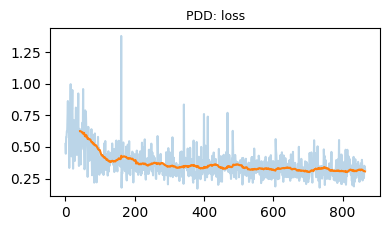

In [26]:
PDD_N = 32
PDD_L_MIN = PDD_L_MAX = PDD_N // STUDENT_NFE    # NFE = N / L


def train_pdd(iters, batch, lr=1e-4, lr_head=3e-5, N=PDD_N, L_min=PDD_L_MIN, L_max=PDD_L_MAX, rk="midpoint"):
    p_lora, p_head = add_lora("pdd"), GRID_HEAD.add_grid("pdd", N)
    print(f"PDD: {n_params(p_lora) / 1e6:.1f}M LoRA + {n_params(p_head) / 1e6:.2f}M head params ({N} heads)")
    student = lambda x, t, c: velocity(x, t, c, "pdd").unflatten(1, (N, -1))
    with torch.no_grad():                         # sanity check: at init every head == teacher velocity
        c = Cond(EVAL_COND.emb[:2], EVAL_COND.mask[:2])
        err = (student(EVAL_NOISE[:2], 0.7, c) - velocity(EVAL_NOISE[:2], 0.7, c)[:, None]).abs().max().item()
    print(f"init check: max |head_k - teacher| = {err:.1e}")
    assert err < 5e-2, "grid heads are not initialised from the teacher's projection"
    opt = torch.optim.AdamW([{"params": p_lora, "lr": lr}, {"params": p_head, "lr": lr_head}],
                            betas=(0.9, 0.99), weight_decay=0.0)
    scaler, grid = new_scaler(), make_grid(N)
    meter = Meter("PDD", iters)
    for it in range(iters):
        if meter.done():
            break
        x0, cond = data_batch(batch)
        loss = pdd_loss(student, teacher_v, x0, cond, grid, L_min, L_max, rk)
        opt_step(loss, opt, scaler, p_lora + p_head)
        meter.log(it, loss=loss.item())
    return meter


meter = train_pdd(P["iters"]["pdd"], P["batch"])
meter.plot()
save_adapter("pdd")

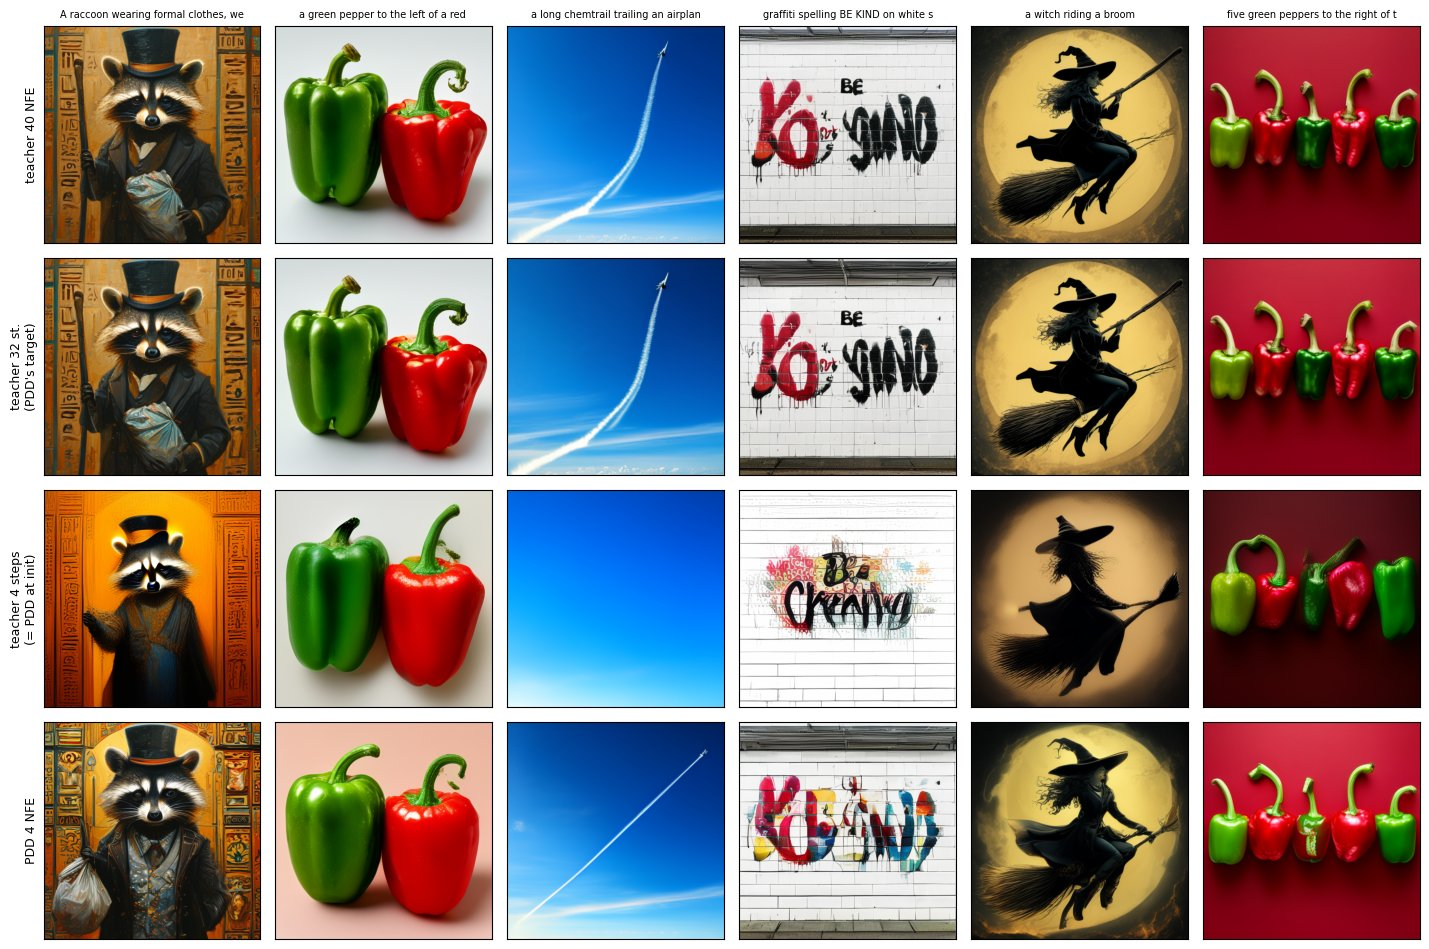

In [27]:
SAMPLERS["PDD"] = lambda c, z: sample_pdd(c, z, L=PDD_N // STUDENT_NFE, N=PDD_N)
OUT["PDD"] = SAMPLERS["PDD"](EVAL_COND, EVAL_NOISE)
show_rows([REF, sample_teacher(EVAL_COND, EVAL_NOISE, steps=PDD_N), REF_FEW, OUT["PDD"]],
          ["teacher 40 NFE", f"teacher {PDD_N} st.\n(PDD's target)", f"teacher {STUDENT_NFE} steps\n(= PDD at init)",
           f"PDD {STUDENT_NFE} NFE"], SHORT)

# 7. Comparison

What to look for:

* **Fidelity to the teacher.** The same noise is used in every row. Trajectory methods (CM, PDD) should keep the teacher's composition; LADD and DMD may change it, because they only match the distribution.
* **Sharpness.** Adversarial and VSD losses produce crisp textures. Pure regression (PDD) is only as sharp as the teacher trajectory it imitates.
* **Diversity.** Reverse-KL (DMD) is mode-seeking, and GANs collapse modes. The PDD paper's main claim is better diversity (they measure it on video).

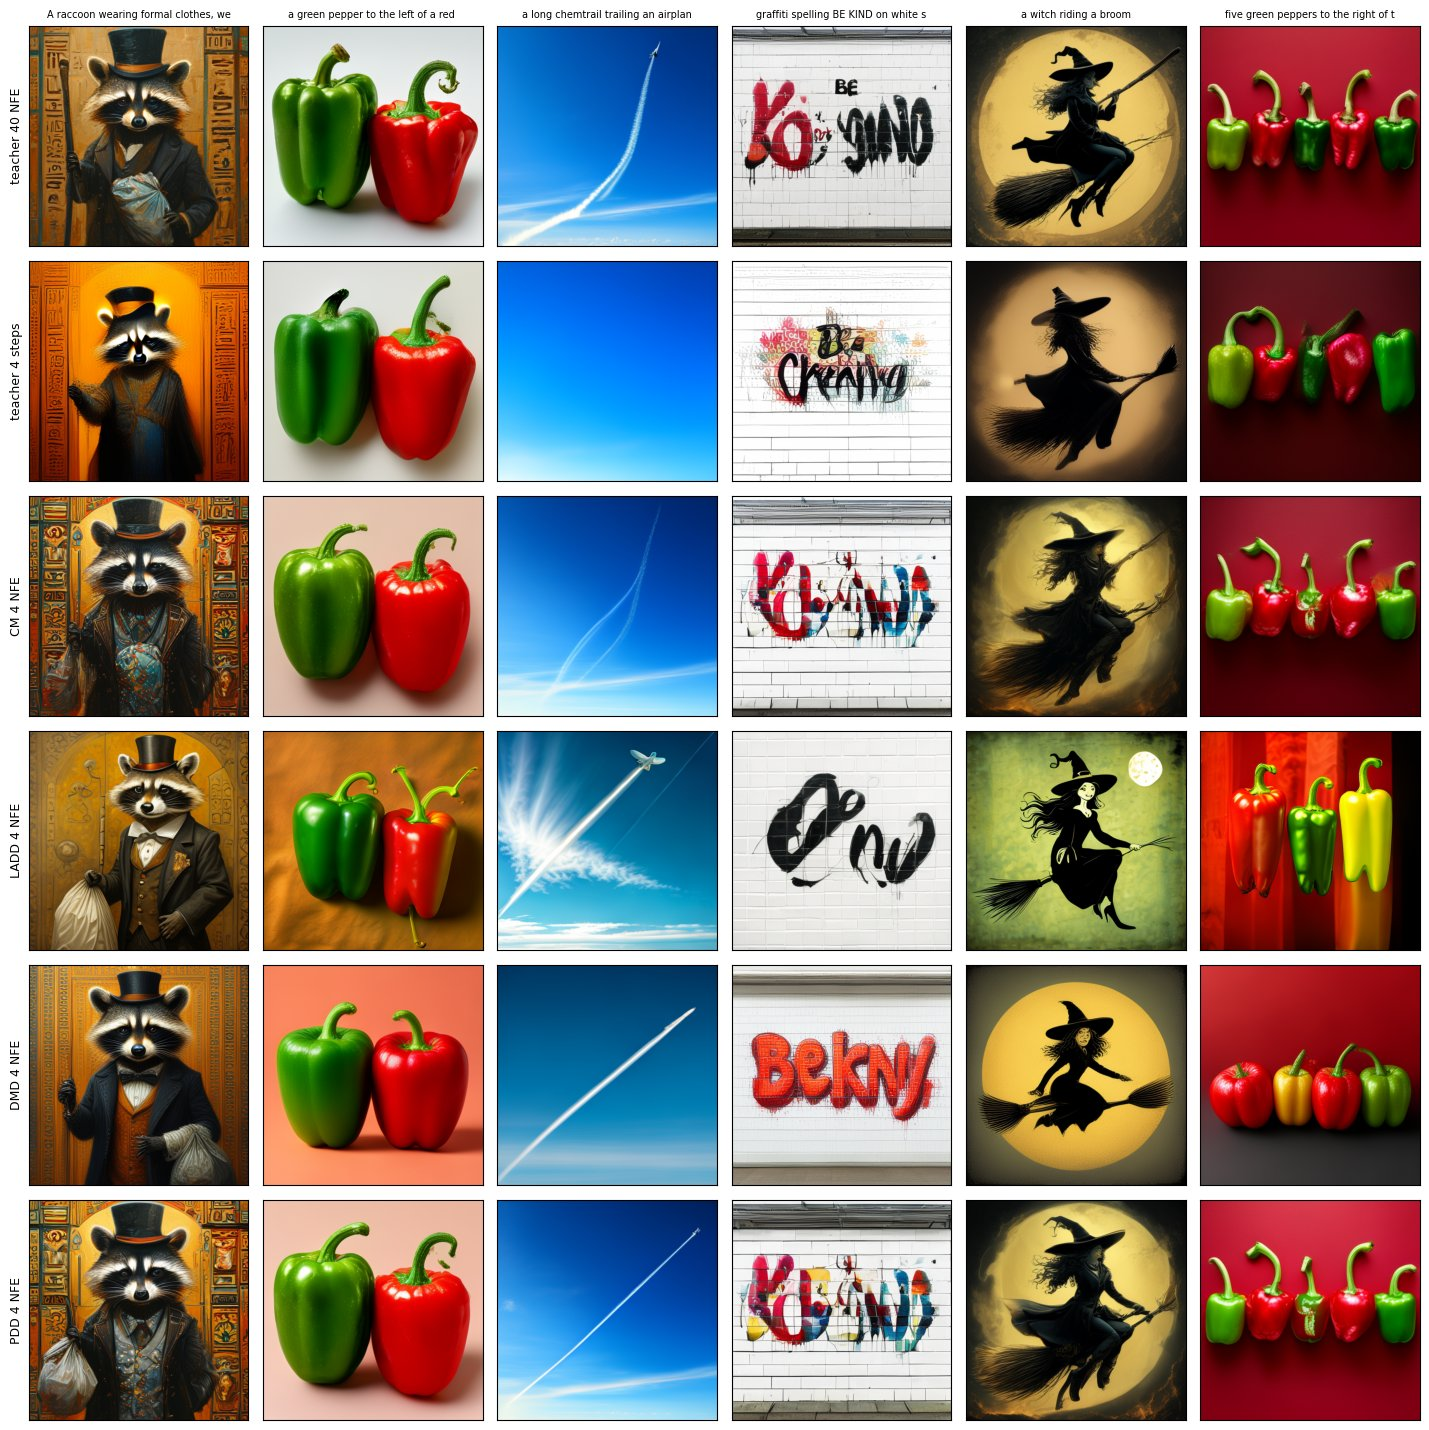

In [28]:
names = list(OUT)
show_rows([REF, REF_FEW] + [OUT[k] for k in names],
          ["teacher 40 NFE", f"teacher {STUDENT_NFE} steps"] + [f"{k} {STUDENT_NFE} NFE" for k in names], SHORT)

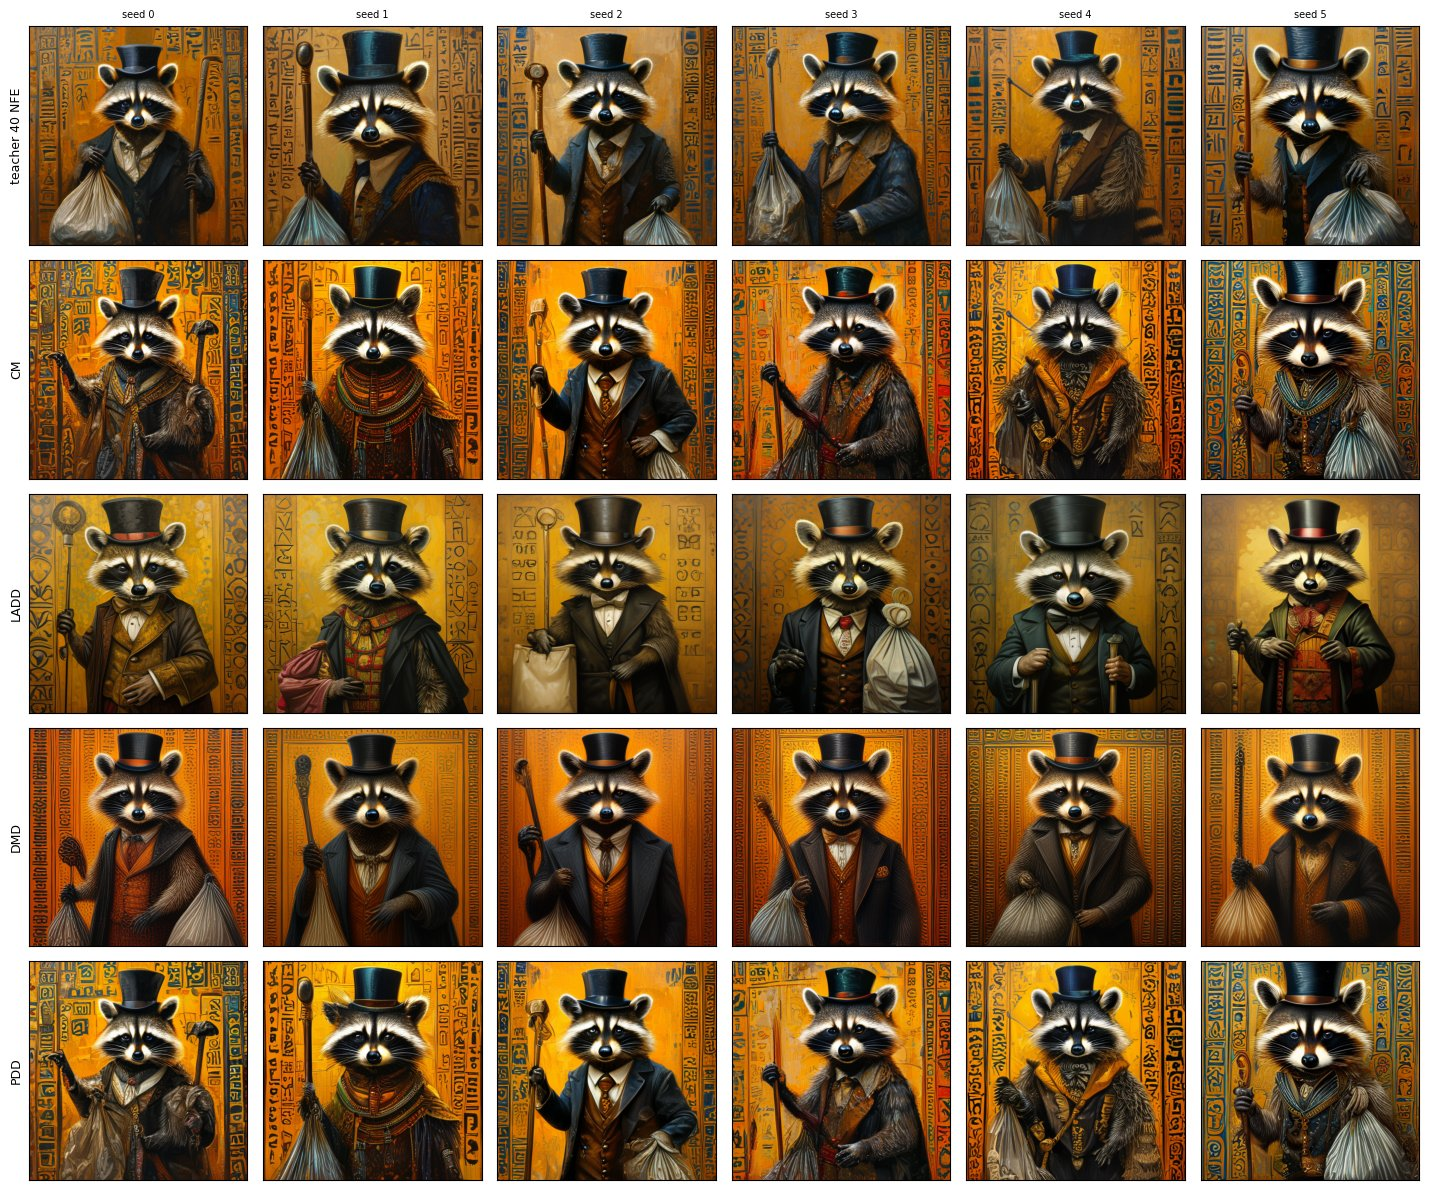

prompt: A raccoon wearing formal clothes, wearing a tophat and holding a cane. The raccoon is holding a garbage bag. Oil painting in the style of Egyptian tomp hieroglyphics.


In [29]:
# diversity: one prompt, 6 seeds per method
div_noise = latent_noise(6, torch.Generator(device=DEVICE).manual_seed(7))
div_cond = Cond(EVAL_COND.emb[:1].expand(6, -1, -1), EVAL_COND.mask[:1].expand(6, -1))
rows = [sample_teacher(div_cond, div_noise)] + [SAMPLERS[k](div_cond, div_noise) for k in names]
show_rows(rows, ["teacher 40 NFE"] + names, [f"seed {i}" for i in range(6)])
print("prompt:", EVAL_PROMPTS[0])

### Numbers (optional, needs a ~600 MB CLIP download)

* **CLIP score**: $100\cdot\cos(\text{image},\text{prompt})$, i.e. text alignment.
* **Diversity**: $1-$ mean pairwise CLIP cosine between seeds of the same prompt.
* **Fidelity**: latent MSE to the teacher's 40-NFE sample from the same noise; low means the student follows the teacher ODE.
* **ms/img**: student sampling time, without VAE decoding.

In [30]:
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


@torch.no_grad()
def clip_embeds(lat, prompts):
    imgs = [(im.numpy() * 255).astype(np.uint8) for im in decode(lat)]
    inp = clip_proc(text=prompts, images=imgs, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    out = clip(**inp)
    return F.normalize(out.image_embeds.float(), dim=-1), F.normalize(out.text_embeds.float(), dim=-1)


SEEDS = 4
n_eval = len(EVAL_IDX)
m_cond = Cond(EVAL_COND.emb.repeat_interleave(SEEDS, 0), EVAL_COND.mask.repeat_interleave(SEEDS, 0))
m_noise = latent_noise(n_eval * SEEDS, torch.Generator(device=DEVICE).manual_seed(99))
m_prompts = [p for p in EVAL_PROMPTS for _ in range(SEEDS)]
ref = sample_teacher(m_cond, m_noise)
few = f"teacher {STUDENT_NFE} steps"
nfe = {few: 2 * STUDENT_NFE, "CM": STUDENT_NFE, "LADD": STUDENT_NFE, "DMD": STUDENT_NFE, "PDD": STUDENT_NFE}
methods = {"teacher 40 NFE": lambda c, z: sample_teacher(c, z),
           few: lambda c, z: sample_teacher(c, z, steps=STUDENT_NFE), **SAMPLERS}
rows = []
for name, fn in methods.items():
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time(); lat = fn(m_cond, m_noise)
    if DEVICE == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) * 1000 / len(m_prompts)
    img_e, txt_e = clip_embeds(lat, m_prompts)
    sims = img_e.view(n_eval, SEEDS, -1) @ img_e.view(n_eval, SEEDS, -1).transpose(1, 2)
    off_diag = sims[:, ~torch.eye(SEEDS, dtype=torch.bool, device=sims.device)]
    rows.append(dict(method=name, NFE=nfe.get(name, 2 * TEACHER_STEPS), ms_per_img=round(ms, 1),
                     clip_score=round(100 * (img_e * txt_e).sum(-1).mean().item(), 2),
                     diversity=round(1 - off_diag.mean().item(), 4),
                     latent_mse_to_teacher=round(F.mse_loss(lat, ref).item(), 4)))
try:
    import pandas as pd
    display(pd.DataFrame(rows).set_index("method"))
except ImportError:
    for r in rows: print(r)

,NFE,ms_per_img,clip_score,diversity,latent_mse_to_teacher
method,,,,,
teacher 40 NFE,40,67.7,32.29,0.0753,0.0000
teacher 4 steps,8,13.5,30.73,0.1174,0.5416
CM,4,23.1,32.67,0.0875,0.4054
LADD,4,21.0,31.95,0.1012,1.4200
DMD,4,21.5,31.25,0.0910,1.0111
PDD,4,22.1,32.88,0.0927,0.4211


# 8. Discussion & exercises

1. **Trajectory vs distribution.** Which students keep the teacher's composition for the same noise? Relate this to `latent_mse_to_teacher`. Why can't LADD or DMD keep it?
2. **CM: `n_fine`.** Train with `n_fine=8` and `n_fine=32`. How do convergence speed and final quality change, and why (propagation length vs teacher ODE error)?
3. **LADD: noise level of the discriminator.** Compare `t_mean=-1` and `t_mean=+1`. What does the student get better at in each case? Try features from only the first half of the blocks; with `_StopForward` this is also faster.
4. **DMD: two time-scale updates.** Set `gen_every=1`. What happens to stability and saturation? Then try `GUIDANCE=7` for the real score only.
5. **DMD2 = DMD + GAN.** Add LADD's discriminator loss to the DMD generator (weight ~1e-2) and train the heads on teacher data. Does it fix DMD's artifacts?
6. **PDD: Euler vs midpoint.** Compare at equal teacher compute: Euler with two `k` per step vs midpoint with one.
7. **PDD data-free (Algorithm 3).** Replace `x_n = add_noise(x0, ...)` with a persistent state that starts from pure noise and is advanced by `L_min` intervals using the student's own heads (detached). This is how the paper trains Qwen-Image, Wan and LTX, and it needs no teacher dataset.
8. **PDD layer fusion.** Show numerically that $W_{n:n+L}=\sum_k \frac{h_k}{t_{n+L}-t_n}W_k$ (same for the bias) gives the same sample as `sample_pdd`, using one standard-size head per block.
9. **1-step students.** Retrain LADD and DMD with `nfe=1`, and PDD with `L_min=L_max=N` (`N=16`). Which method degrades least?